In [2]:
from flask import Flask, jsonify, request
from flask_cors import CORS
import sqlite3
from collections import deque
from pathlib import Path

import graph as g
import graph_stats as gs
import word_graph_analysis as wga
import matplotlib.pyplot as plt

from flask import Flask, jsonify, request
from flask_cors import CORS
import sqlite3
from collections import deque
from pathlib import Path
import graph_stats as gs
import languageprocessing as lp

import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.decomposition import PCA


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\André\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [3]:
DBS_PATH = "../DatabaseBackups"
API_DBS_PATH = "../DatabaseBackups/API"
LOCAL_DBS_PATH = "../DatabaseBackups/Local"

db_files = list(Path(DBS_PATH).glob("*.db"))
for db_file in db_files:
    print(f"Found database file: {db_file.name}")

final_local_db = db_files[-1]  # Assuming the last file is the most recent
print(f"Using the most recent database file: {final_local_db.name}")

final_api_db = db_files[-2]  # Assuming the second last file is the most recent API database
print(f"Using the most recent API database file: {final_api_db.name}")

api_files = list(Path(API_DBS_PATH).glob("*"))
for api_file in api_files:
    print(f"Found API database file: {api_file.name}")

local_files = list(Path(LOCAL_DBS_PATH).glob("*.db"))
for local_file in local_files:
    print(f"Found Local database file: {local_file.name}")



with open("ogden.txt", "r") as f:
    text = f.read()


words = text.split(" ")
for i in range(len(words)):
    words[i] = words[i].strip()

print(words)

Found database file: api_database.db
Found database file: local_database.db
Using the most recent database file: local_database.db
Using the most recent API database file: api_database.db
Found API database file: 20260713_183720_cycle_1_start.txt
Found API database file: 20260714_032935_cycle_1.db
Found API database file: 20260714_043840_cycle_2.db
Found API database file: 20260714_232034_cycle_3_start.txt
Found API database file: 20260715_072131_cycle_3.db
Found API database file: 20260716_042930_cycle_4_start.txt
Found API database file: 20260716_101344_cycle_4.db
Found API database file: 20260716_150606_cycle_5.db
Found API database file: 20260717_113438_cycle_6_start.txt
Found API database file: 20260717_183130_cycle_6.db
Found API database file: 20260718_052342_cycle_7.db
Found Local database file: 20260714_050552_database_backup_0_local_ogden_cycle.db
Found Local database file: 20260714_091557_database_backup_1_local_cycle.db
Found Local database file: 20260714_151445_database_ba

# Ogden en Espanol from translating English Ogden

In [3]:
db_file = db_files[-1]
spanish_ogden = set()

conn = sqlite3.connect(db_file)
conn.row_factory = sqlite3.Row
cursor = conn.cursor()

placeholders = ",".join("?" for _ in words)

cursor.execute(f"""
    SELECT 
        CASE WHEN w1.word = w.word THEN w2.word ELSE w1.word END AS translated_word,
        CASE WHEN w1.word = w.word THEN w2.language ELSE w1.language END AS translated_language
    FROM words w
    JOIN relations r ON (r.word1_id = w.id OR r.word2_id = w.id)
    JOIN words w1 ON r.word1_id = w1.id
    JOIN words w2 ON r.word2_id = w2.id
    WHERE w.word IN ({placeholders})
      AND r.relation_type = 'translation'
""", words)

for row in cursor.fetchall():
    if row["translated_language"] == "ES":
        spanish_ogden.add(row["translated_word"])


In [4]:
import random

true_spanish_ogden = set()
i = 1
for ogden in spanish_ogden:
    print(str(i) + "/" + str(len(spanish_ogden)))
    i += 1
    lp_ogden = lp.preprocess_text(ogden)["lemmatized"]
    if ogden is not None and len(lp_ogden) > 0:
        true_spanish_ogden.add(lp_ogden[0])

print(len(true_spanish_ogden))




1/6602
2/6602
3/6602
4/6602
5/6602
6/6602
7/6602
8/6602
9/6602
10/6602
11/6602
12/6602
13/6602
14/6602
15/6602
16/6602
17/6602
18/6602
19/6602
20/6602
21/6602
22/6602
23/6602
24/6602
25/6602
26/6602
27/6602
28/6602
29/6602
30/6602
31/6602
32/6602
33/6602
34/6602
35/6602
36/6602
37/6602
38/6602
39/6602
40/6602
41/6602
42/6602
43/6602
44/6602
45/6602
46/6602
47/6602
48/6602
49/6602
50/6602
51/6602
52/6602
53/6602
54/6602
55/6602
56/6602
57/6602
58/6602
59/6602
60/6602
61/6602
62/6602
63/6602
64/6602
65/6602
66/6602
67/6602
68/6602
69/6602
70/6602
71/6602
72/6602
73/6602
74/6602
75/6602
76/6602
77/6602
78/6602
79/6602
80/6602
81/6602
82/6602
83/6602
84/6602
85/6602
86/6602
87/6602
88/6602
89/6602
90/6602
91/6602
92/6602
93/6602
94/6602
95/6602
96/6602
97/6602
98/6602
99/6602
100/6602
101/6602
102/6602
103/6602
104/6602
105/6602
106/6602
107/6602
108/6602
109/6602
110/6602
111/6602
112/6602
113/6602
114/6602
115/6602
116/6602
117/6602
118/6602
119/6602
120/6602
121/6602
122/6602
123/6602
1

In [5]:
sample = random.sample(list(true_spanish_ogden), 100)
print(sample)

['desmayo', 'oseir', 'vinatico', 'auriculado', 'rentabilidad', 'grip', 'integer', 'ramificación', 'cordillerano', 'pmpo', 'pensante', 'locacion', 'conferencio', 'ccpp', 'top', 'adstricción', 'zarco', 'osal', 'clima', 'gótico', 'pelo', 'iudex', 'platerio', 'cabeza', 'llorador', 'gancho', 'lycaenidae', 'arado', 'chaw', 'constipado', 'transferencia', 'escritorio', 'maternidad', 'leptoconopidae', 'competidor', 'subanillo', 'hidroavión', 'spacir', 'ahumado', 'sustrato', 'decusada', 'cuaquero', 'submarino', 'śama', 'proceso', 'taksim', 'aviacion', 'censura', 'trusar', 'cucharear', 'duración', 'radicular', 'aceite', 'incomunicación', 'precio', 'bache', 'equipo', 'destrucción', 'ecactán', 'saludable', 'secreccion', 'psd', 'cabello', 'turístico', 'lipidico', 'caber', 'intermisión', 'dieseleléctrico', 'ilah', 'dispensa', 'inventario', 'saber', 'cuatreño', 'bodeguero', 'entrada', 'mayo', 'replicación', 'oceanódroma', 'ecologismo', 'licenido', 'chaveta', 'explicación', 'francmasonico', 'fluidodina

# Comparing Ogden with full graph & AI MODELS


## FUNCTIONS

In [4]:
# FEATURES = ["degree", "pagerank", "triangles", "k_core", "clustering", "betweenness", "louvain_community_id", "average_neighbor_degree"]
# FEATURES = ["degree", "pagerank", "clustering", "betweenness","average_neighbor_degree"]
FEATURES = ["degree", "pagerank", "clustering", "betweenness"]

In [77]:
def pca_and_bestk(X, summary, mode="words", title="Elbow Method"):
    StandardScaler()
    scaler = StandardScaler()


    word_index = {}
    i = 0
    for word in summary["degree_list_unsorted"]:
        word_index[word[0]] = i
        i += 1

    X_scaled = scaler.fit_transform(X)
    df = pd.DataFrame(X_scaled, columns=FEATURES)


    if mode == "words":
        df["word"] = [word[0][:-2] for word in summary["degree_list_unsorted"]]
        df["y"] = [1 if word[0][:-2] in words else 0 for word in summary["degree_list_unsorted"]]
    elif mode == "all":
        df["word"] = [word[0] for word in summary["degree_list_unsorted"]]
        df["y"] = [1 if word[0] in words else 0 for word in summary["degree_list_unsorted"]]

    X_scaled = df[FEATURES].values
    pca_full = PCA()
    pca_full.fit(X_scaled)


    cumulative_var = np.cumsum(pca_full.explained_variance_ratio_)
    print("Cumulative explained variance by component:")
    for idx, var in enumerate(cumulative_var, start=1):
        print(f"  {idx} components: {var:.3f}")

    # Pick n_components to retain ~90-95% of variance (adjust based on printout above)
    n_components = np.argmax(cumulative_var >= 0.90) + 1
    print(f"\nUsing {n_components} components to retain >=90% variance")

    pca_2d = PCA(n_components=2)
    X_pca_2d = pca_2d.fit_transform(X_scaled)
    df["pca1"] = X_pca_2d[:, 0]
    df["pca2"] = X_pca_2d[:, 1]

    # pca_2d.components_ has shape (n_components, n_features)
    # Row 0 = PC1 loadings, Row 1 = PC2 loadings
    loadings = pd.DataFrame(
        pca_2d.components_.T,  # transpose so features are rows
        columns=["PC1", "PC2"],
        index=FEATURES  # your original feature names
    )

    # Sort by PC2 to see which features drive it most (positive and negative)
    pc2_sorted = loadings.sort_values("PC2", ascending=False)
    print(pc2_sorted)

    scores = []
    wcss = []

    for k in range(2, 11):
        kmeans = KMeans(n_clusters=k, random_state=2026)
        kmeans.fit(X_pca_2d)
        wcss.append(kmeans.inertia_)
        print(f"k = {k}, WCSS = {kmeans.inertia_:.2f}")

    # Plot the elbow curve
    plt.figure(figsize=(6, 4))
    plt.plot(range(2, 11), wcss, marker='o')
    plt.xlabel("Número de clusteres (k)")
    plt.ylabel("WCSS")
    plt.title(f"{title} Método del codo")
    plt.xticks(range(2, 11))
    plt.grid(True)
    plt.show()


    return X_pca_2d, df, pca_2d, word_index, scaler


In [78]:
def compare_ogden(db_file, mode, title):

    conn = sqlite3.connect(db_file)
    conn.row_factory = sqlite3.Row
    word_to_ids = gs.get_node_ids_for_words(conn, words, language="EN", mode=mode)

    G = g.build_graph(conn, language="EN", mode=mode)
    analysis = wga.analyze_word_group(G, word_to_ids, label="ogden words", mode=mode, language="EN")
    wga.print_word_group_analysis(analysis)
    results = wga.core_word_metrics(G, words, mode=mode, language="EN")


    for key in results["summary"].keys():
        if "percentile" in key:
            print(f"{key}: {results['summary'][key]}")

    num = 1000
    for key in results["summary"]:
        if "list" in key and "unsorted" not in key:
            hits = 0
            for word, value in results["summary"][key][:num]:
                if mode == "words":
                    if word[:-2] in words:
                        hits += 1
                else:
                    if word in words:
                        hits += 1
                    
        
            print(f"{key}: {hits / len(words) * 100:.2f}% of Ogden --- Ogden was {hits / num * 100:.2f}% of the top {num} words")
            
    X = []
    print(results["node_metrics"].keys())
    for word in G.nodes():
        row = [
            results["node_metrics"][word][feature]
            for feature in FEATURES
        ]
        X.append(row)

    X_pca_2d, df, pca_2d, word_index, scaler = pca_and_bestk(X, results["summary"], mode=mode, title=title)


    return_dict = {
        "X": X,
        "X_pca_2d": X_pca_2d,
        "df": df,
        "pca_2d": pca_2d,
        "word_index": word_index,
        "node_metrics": results["node_metrics"],
        "summary": results["summary"],
        "scaler": scaler
    }

    return return_dict


In [79]:
def best_f1_for_k(labels, is_ogden, k):
    total_ogden = is_ogden.sum()
    tp, fp = cluster_stats(labels, is_ogden, k)

    local_precision = np.divide(tp, tp + fp, out=np.zeros_like(tp, dtype=float), where=(tp+fp) > 0)
    order = np.argsort(-local_precision)

    cum_tp = cum_fp = 0
    best_f1, best_subset = 0.0, []
    subset = []
    for c in order:
        cum_tp += tp[c]
        cum_fp += fp[c]
        subset.append(int(c))

        precision = cum_tp / (cum_tp + cum_fp) if (cum_tp + cum_fp) > 0 else 0
        recall = cum_tp / total_ogden if total_ogden > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

        if f1 > best_f1:
            best_f1, best_subset = f1, subset.copy()

    return best_f1, best_subset

def cluster_stats(labels, is_ogden, k):
    tp = np.array([(is_ogden & (labels == c)).sum() for c in range(k)])
    fp = np.array([(~is_ogden & (labels == c)).sum() for c in range(k)])
    return tp, fp

In [80]:
from sklearn.metrics import confusion_matrix



def plot_classification_report(y_true, y_pred, report, f1_score, title="", output_dir="."):

    cm = confusion_matrix(y_true, y_pred, labels=[True, False])
    tp, fn, fp, tn = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # --- Confusion matrix heatmap ---
    ax = axes[0]
    matrix = np.array([[tp, fn], [fp, tn]])
    labels = np.array([["TP", "FN"], ["FP", "TN"]])
    im = ax.imshow(matrix, cmap="Blues")

    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{labels[i, j]}\nn={matrix[i, j]}",
                    ha="center", va="center", fontsize=13,
                    color="white" if matrix[i, j] > matrix.max() / 2 else "black")

    ax.set_xticks([0, 1]); ax.set_xticklabels(["Pred Ogden", "Pred No Ogden"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["True Ogden", "True No Ogden"])
    ax.set_title(f"{title} Matriz de confusión")


    # --- Confusion matrix heatmap ---
    ax = axes[0]
    matrix = np.array([[tp, fn], [fp, tn]])
    labels = np.array([["TP", "FN"], ["FP", "TN"]])
    im = ax.imshow(matrix, cmap="Blues")

    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{labels[i, j]}\nn={matrix[i, j]}",
                    ha="center", va="center", fontsize=13,
                    color="white" if matrix[i, j] > matrix.max() / 2 else "black")

    ax.set_xticks([0, 1]); ax.set_xticklabels(["Pred Ogden", "Pred No Ogden"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["True Ogden", "True No Ogden"])
    ax.set_title(f"{title} Matriz de confusión")

    ax2 = axes[1]
    classes = ["No Ogden", "Ogden"]
    metrics = ["precision", "recall", "f1-score"]
    x = np.arange(len(classes))
    width = 0.25

    for i, metric in enumerate(metrics):
        values = [report[c][metric] for c in classes]
        bars = ax2.bar(x + i * width, values, width, label=metric)
        ax2.bar_label(bars, fmt="%.2f", fontsize=9)

    ax2.set_xticks(x + width)
    ax2.set_xticklabels(classes)
    ax2.set_ylim(0, 1.05)
    ax2.set_ylabel("Score")
    ax2.set_title(f"{title} reporte de clasificación (F1={f1_score:.3f})")
    ax2.legend()

    plt.tight_layout()
    plt.savefig(f"{output_dir}/{title}_classification_report.png", dpi=300)


In [81]:
from sklearn.metrics import confusion_matrix, classification_report
from torch import mode

def kmeans_schedule(X, df, pca_2d, word_index, best_k, title="", output_dir="kmeans" , show=True):

    df = df.copy(deep=True) 

    kmeans = KMeans(n_clusters=best_k, random_state=2026)
    labels = kmeans.fit_predict(X)

    df['cluster'] = labels

    # Boolean mask for Ogden vs not
    is_ogden = df["y"] == 1

    f1_score, best_subset = best_f1_for_k(labels, df["y"] == 1, best_k)
    display(f"Best F1 score: {f1_score:.3f}")

    # Filter to only points within the PC1 range you want to display
    excluded_points = 25
    plot_df = df[df["pca1"] <= excluded_points]

    # Now split the *filtered* data into two groups
    not_ogden = plot_df[plot_df["y"] == 0]
    ogden = plot_df[plot_df["y"] == 1]

    plt.figure(figsize=(10, 7))

    # Plot non-highlighted points first (so highlighted ones sit on top)
    plt.scatter(
        not_ogden["pca1"], not_ogden["pca2"],
        color="lightgray", s=50, alpha=0.6,
        edgecolors="k", linewidths=0.3,
        label="No Ogden"
    )

    # Plot highlighted points (y == 1) with a distinct color, bigger size
    plt.scatter(
        ogden["pca1"], ogden["pca2"],
        color="crimson", s=50, alpha=0.2,
        edgecolors="black", linewidths=0.8,
        label="Ogden"
    )

    plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]:.1%})")
    plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]:.1%})")
    plt.title(f"{title} Ogden vs No Ogden proyectados en los componentes PCA\n(puntos con PC1 > {excluded_points} excluidos)")
    plt.legend()
    plt.tight_layout()


    plt.savefig(f"{output_dir}/{title}_kmeans_plot.png", dpi=300)
    if show:
        plt.show()

    
    plt.figure(figsize=(10, 7))

    
    scatter = plt.scatter(
        plot_df["pca1"], plot_df["pca2"],
        c=plot_df["cluster"], cmap="tab10",
        s=60, alpha=0.8, edgecolors="k", linewidths=0.3
    )
    plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]:.1%})")
    plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]:.1%})")
    plt.title(f"{title} Clusters de Kmeans (k={best_k}) proyectados en los componentes PCA\n(puntos con PC1 > {excluded_points} excluidos)")
    plt.colorbar(scatter, label="Cluster")
    plt.tight_layout()

    

    plt.savefig(f"{output_dir}/{title}_kmeans_clusters.png", dpi=300)
    if show:
        plt.show()

    if mode == "all":
        df[df["y"] == 1]

    ogden_label_count = df["cluster"][df["y"] == 1].value_counts().to_dict()
    ogden_label_count = {str(i): ogden_label_count.get(i, 0) for i in range(best_k)}


    total_label_count = df["cluster"][df["y"] == 0].value_counts().to_dict()
    total_label_count = {str(i): total_label_count.get(i, 0) for i in range(best_k)}
    
    print("\n Ogden Counts:")
    for label, count in ogden_label_count.items():
        print(f"Cluster {label}: {count}")
        #if label==5 and word not in words:
            #print(word)


    print("\n Non Ogden Counts:")
    for label, count in total_label_count.items():
        print(f"Cluster {label}: {count} - {ogden_label_count[label]/(ogden_label_count[label] + total_label_count[label]) * 100:.2f}% of Ogden words in this cluster")

    

    for label in best_subset:
        sample = df[(df["cluster"] == label)].sample(n=min(10, len(df[(df["cluster"] == label)])), random_state=2026)
        print(f"\nSample Ogden words from cluster {label}: {sample["word"].tolist()}")
    y_pred = np.isin(labels, best_subset)
    y_true = df["y"] == 1   

    plot_classification_report(y_true=y_true, y_pred=y_pred, report=classification_report(y_true, y_pred, target_names=["No Ogden", "Ogden"], output_dict=True),
                                f1_score=f1_score, title=title, output_dir=output_dir)
    
    return kmeans




In [82]:
def fix_df_y_all(df):
    display(f"Before fixing, y=1 count: {df['y'].sum()}")
    positive = set(df.loc[df["y"] == 1, "word"])

    mask = df["word"].apply(
        lambda w: any(w.startswith(p + "_") for p in positive)
    )

    df.loc[mask, "y"] = 1
    display(f"After fixing, y=1 count: {df['y'].sum()}")


## API WORDS

=== ogden words ===
Nodes analyzed: 598

Degree mean=140.778 median=92.0 stdev=180.701
Mean degree percentile: 98.63

Computing Louvain communities...
degree_mean_percentile: 98.3
degree_median_percentile: 96.67
eigenvector_mean_percentile: 97.84
eigenvector_median_percentile: 96.12
pagerank_mean_percentile: 98.33
pagerank_median_percentile: 96.72
k_core_mean_percentile: 94.88
k_core_median_percentile: 96.17
clustering_mean_percentile: 44.51
clustering_median_percentile: 41.06
triangles_mean_percentile: 98.78
triangles_median_percentile: 96.71
betweenness_mean_percentile: 98.67
betweenness_median_percentile: 96.27
average_neighbor_degree_mean_percentile: 48.38
average_neighbor_degree_median_percentile: 44.7
louvain_community_size_mean_percentile: 46.89
louvain_community_size_median_percentile: 64.11
degree_list: 54.22% of Ogden --- Ogden was 41.80% of the top 1000 words
eigenvector_list: 49.29% of Ogden --- Ogden was 38.00% of the top 1000 words
pagerank_list: 54.60% of Ogden --- Ogden

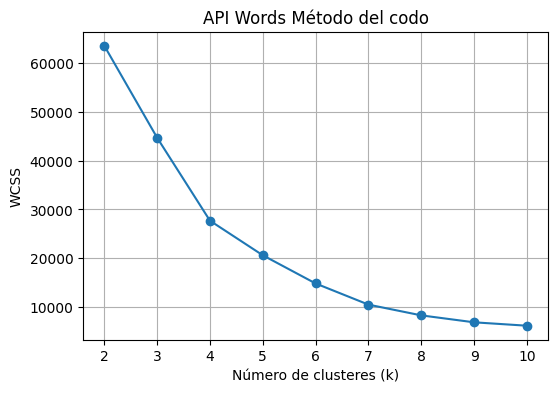

In [83]:
result_api_words = compare_ogden(final_api_db, mode="words", title="API Words")

'Best F1 score: 0.479'


 Ogden Counts:
Cluster 0: 393
Cluster 1: 5
Cluster 2: 15
Cluster 3: 0
Cluster 4: 69
Cluster 5: 289

 Non Ogden Counts:
Cluster 0: 667 - 37.08% of Ogden words in this cluster
Cluster 1: 5 - 50.00% of Ogden words in this cluster
Cluster 2: 5970 - 0.25% of Ogden words in this cluster
Cluster 3: 1105 - 0.00% of Ogden words in this cluster
Cluster 4: 40 - 63.30% of Ogden words in this cluster
Cluster 5: 17976 - 1.58% of Ogden words in this cluster

Sample Ogden words from cluster 4: ['short', 'charge', 'movement', 'base', 'place', 'get', 'give', 'another', 'group', 'hold']

Sample Ogden words from cluster 1: ['state', 'make', 'especially', 'cause', 'person', 'use', 'usually', 'act', 'one', 'something']

Sample Ogden words from cluster 0: ['trace', 'press', 'current', 'measure', 'regard', 'similar', 'tie', 'book', 'science', 'determination']


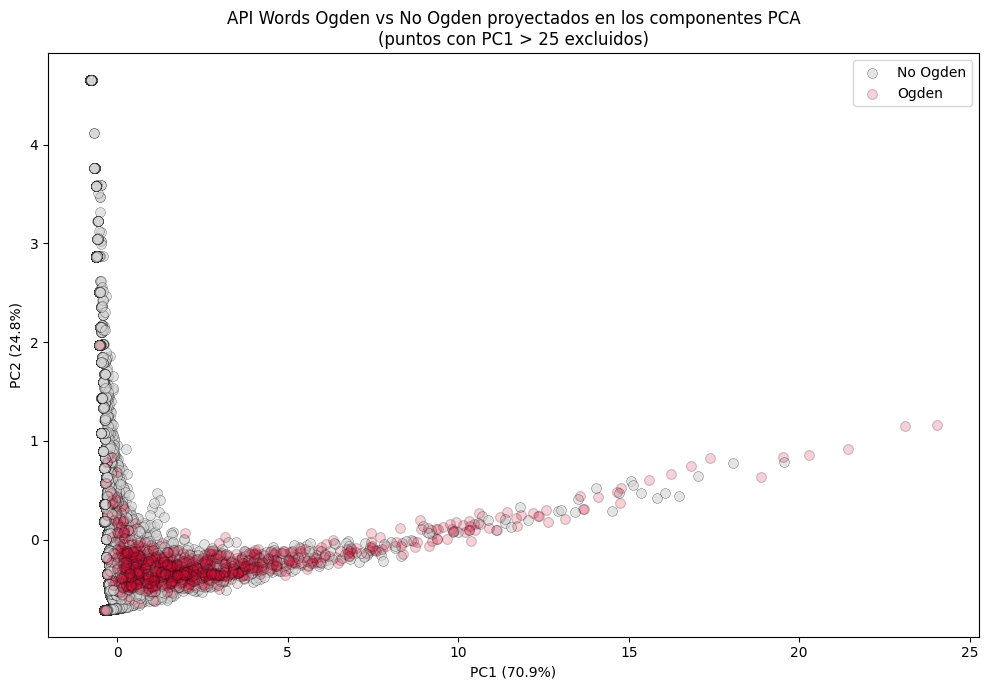

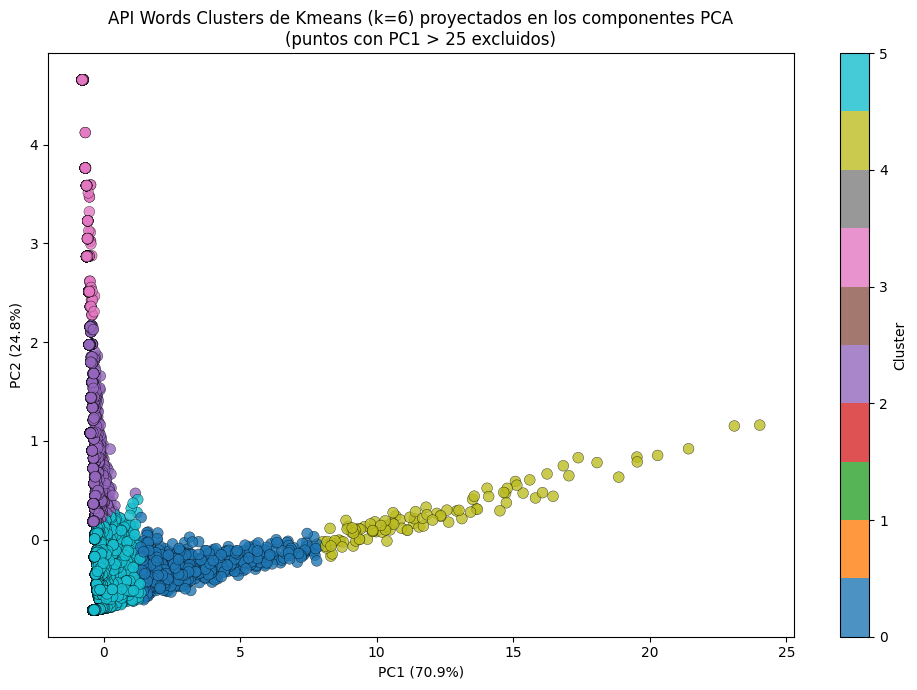

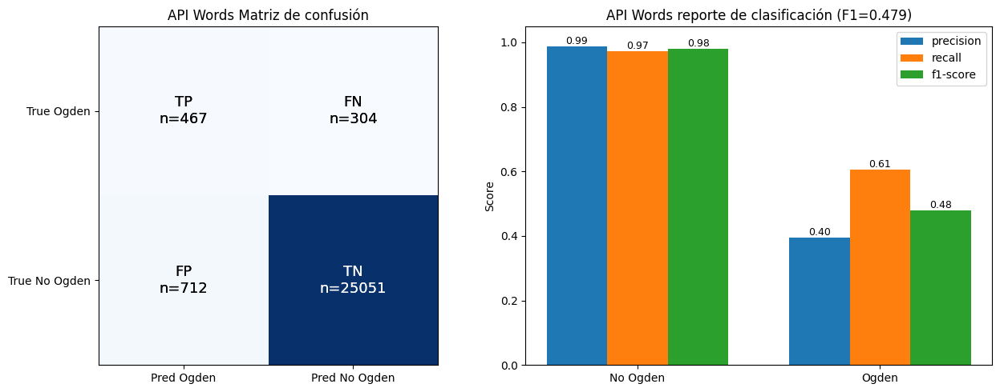

In [84]:
best_k_api_words = 6

kmeans_api_words = kmeans_schedule(
    result_api_words["X_pca_2d"],
    result_api_words["df"],
    result_api_words["pca_2d"],
    result_api_words["word_index"],
    title="API Words",
    best_k=best_k_api_words,
    output_dir="kmeans/api_words",
    show=False
)

## API ALL

=== ogden words ===
Nodes analyzed: 7542

Degree mean=6.635 median=5.0 stdev=13.645
Mean degree percentile: 74.42

Computing Louvain communities...
degree_mean_percentile: 99.59
degree_median_percentile: 99.05
eigenvector_mean_percentile: 94.06
eigenvector_median_percentile: 85.0
pagerank_mean_percentile: 99.59
pagerank_median_percentile: 99.02
k_core_mean_percentile: 90.41
k_core_median_percentile: 99.6
clustering_mean_percentile: 94.11
clustering_median_percentile: 93.81
triangles_mean_percentile: 98.83
triangles_median_percentile: 93.81
betweenness_mean_percentile: 99.57
betweenness_median_percentile: 98.05
average_neighbor_degree_mean_percentile: 28.43
average_neighbor_degree_median_percentile: 28.05
louvain_community_size_mean_percentile: 60.74
louvain_community_size_median_percentile: 72.11
degree_list: 44.75% of Ogden --- Ogden was 34.50% of the top 1000 words
eigenvector_list: 6.61% of Ogden --- Ogden was 5.10% of the top 1000 words
pagerank_list: 43.45% of Ogden --- Ogden was 

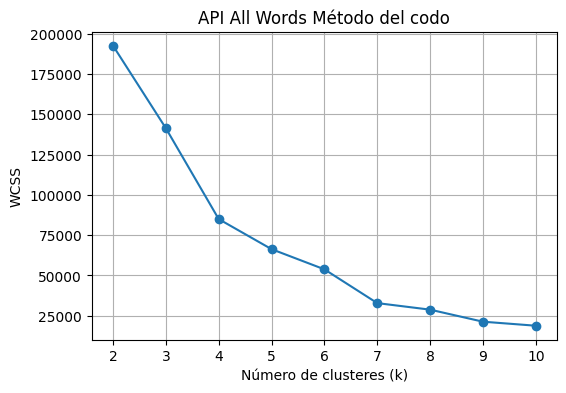

In [85]:
result_api_all = compare_ogden(final_api_db, mode="all", title="API All Words")

'Before fixing, y=1 count: 595'

'After fixing, y=1 count: 6794'

'Best F1 score: 0.151'


 Ogden Counts:
Cluster 0: 6380
Cluster 1: 10
Cluster 2: 91
Cluster 3: 57
Cluster 4: 2
Cluster 5: 0
Cluster 6: 243
Cluster 7: 2
Cluster 8: 9

 Non Ogden Counts:
Cluster 0: 74767 - 7.86% of Ogden words in this cluster
Cluster 1: 6 - 62.50% of Ogden words in this cluster
Cluster 2: 1831 - 4.73% of Ogden words in this cluster
Cluster 3: 54 - 51.35% of Ogden words in this cluster
Cluster 4: 1 - 66.67% of Ogden words in this cluster
Cluster 5: 59 - 0.00% of Ogden words in this cluster
Cluster 6: 528 - 31.52% of Ogden words in this cluster
Cluster 7: 2 - 50.00% of Ogden words in this cluster
Cluster 8: 391 - 2.25% of Ogden words in this cluster

Sample Ogden words from cluster 4: ['use', 'something', 'make']

Sample Ogden words from cluster 1: ['time', 'manner', 'part', 'small', 'usually', 'place', 'move_bn:00082285v', 'relate', 'give', 'take']

Sample Ogden words from cluster 3: ['event', 'power', 'consist', 'purpose', 'together', 'high', 'physical', 'expression_bn:00006386n', 'piece', 'cha

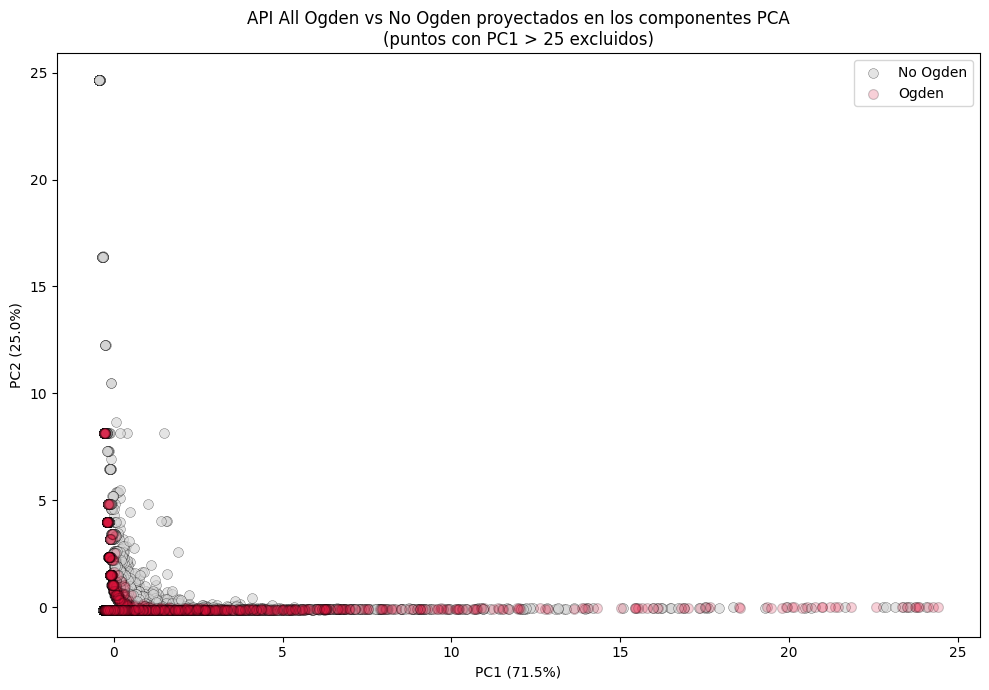

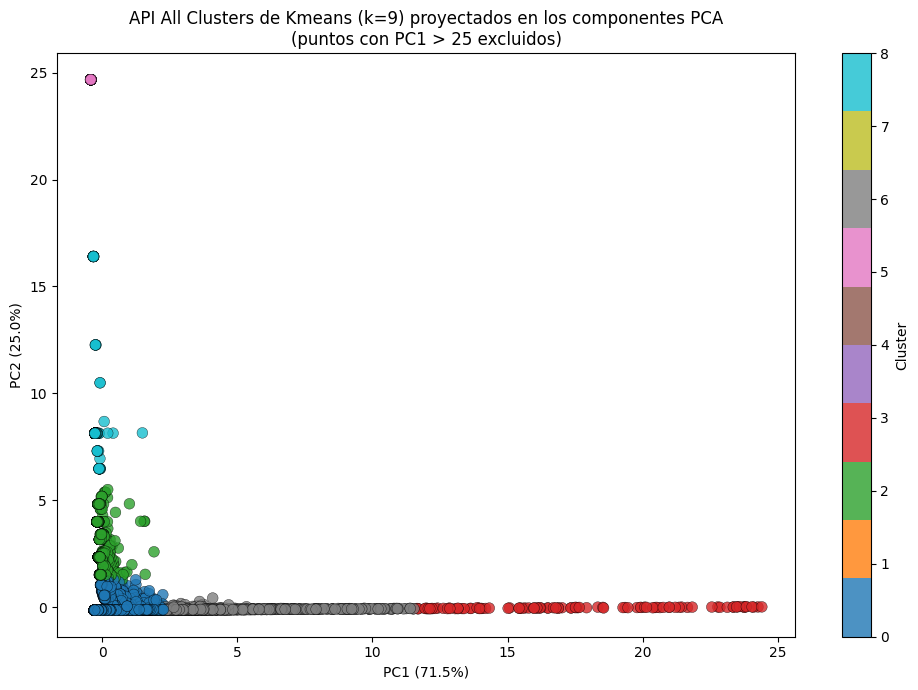

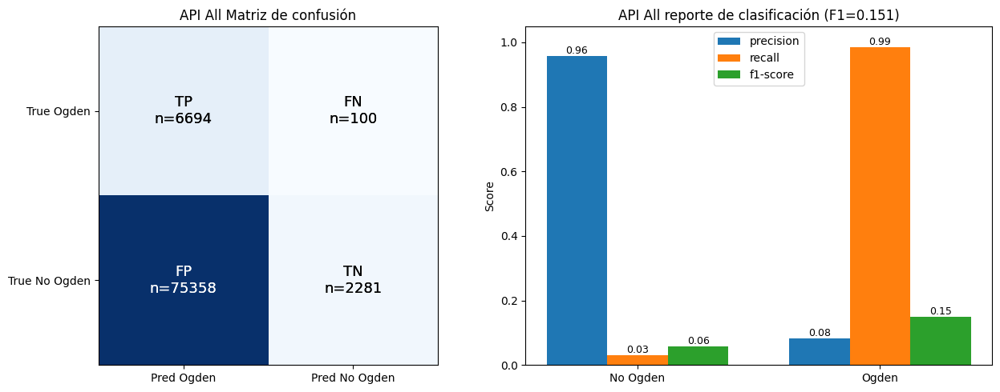

In [86]:
best_k_api_all = 9

fix_df_y_all(result_api_all["df"])

kmeans_api_all = kmeans_schedule(
    result_api_all["X_pca_2d"],
    result_api_all["df"],
    result_api_all["pca_2d"],
    result_api_all["word_index"],
    title="API All",
    best_k=best_k_api_all,
    output_dir="kmeans/api_all",
    show=False
)

## LOCAL WORDS

=== ogden words ===
Nodes analyzed: 571

Degree mean=394.673 median=203 stdev=646.795
Mean degree percentile: 99.55

Computing Louvain communities...
degree_mean_percentile: 99.41
degree_median_percentile: 98.73
eigenvector_mean_percentile: 99.31
eigenvector_median_percentile: 98.65
pagerank_mean_percentile: 99.43
pagerank_median_percentile: 98.73
k_core_mean_percentile: 97.89
k_core_median_percentile: 98.79
clustering_mean_percentile: 11.55
clustering_median_percentile: 10.35
triangles_mean_percentile: 99.55
triangles_median_percentile: 98.59
betweenness_mean_percentile: 99.66
betweenness_median_percentile: 98.6
average_neighbor_degree_mean_percentile: 24.46
average_neighbor_degree_median_percentile: 20.78
louvain_community_size_mean_percentile: 58.54
louvain_community_size_median_percentile: 79.1
degree_list: 43.84% of Ogden --- Ogden was 33.80% of the top 1000 words
eigenvector_list: 42.67% of Ogden --- Ogden was 32.90% of the top 1000 words
pagerank_list: 43.71% of Ogden --- Ogden 

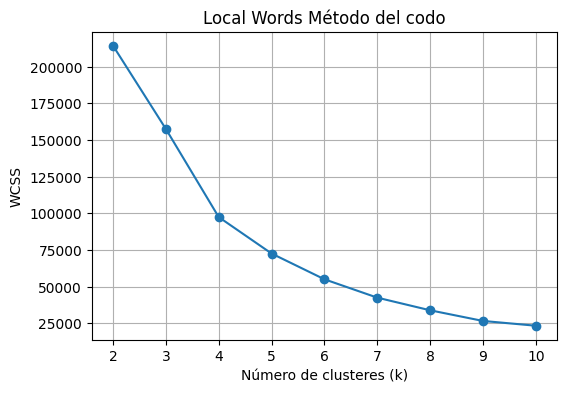

In [87]:
result_local_words = compare_ogden(final_local_db, mode="words", title="Local Words")

'Best F1 score: 0.394'


 Ogden Counts:
Cluster 0: 10
Cluster 1: 9
Cluster 2: 287
Cluster 3: 21
Cluster 4: 1
Cluster 5: 1
Cluster 6: 99
Cluster 7: 343
Cluster 8: 0

 Non Ogden Counts:
Cluster 0: 39088 - 0.03% of Ogden words in this cluster
Cluster 1: 6 - 60.00% of Ogden words in this cluster
Cluster 2: 28197 - 1.01% of Ogden words in this cluster
Cluster 3: 35 - 37.50% of Ogden words in this cluster
Cluster 4: 3 - 25.00% of Ogden words in this cluster
Cluster 5: 19693 - 0.01% of Ogden words in this cluster
Cluster 6: 138 - 41.77% of Ogden words in this cluster
Cluster 7: 974 - 26.04% of Ogden words in this cluster
Cluster 8: 4166 - 0.00% of Ogden words in this cluster

Sample Ogden words from cluster 1: ['language', 'plant', 'people', 'make', 'genus', 'term', 'form', 'type', 'person', 'system']

Sample Ogden words from cluster 6: ['tree', 'blood', 'characteristic', 'thing', 'may', 'piece', 'represent', 'change', 'variety', 'alphabet']

Sample Ogden words from cluster 3: ['unit', 'often', 'animal', 'common', '

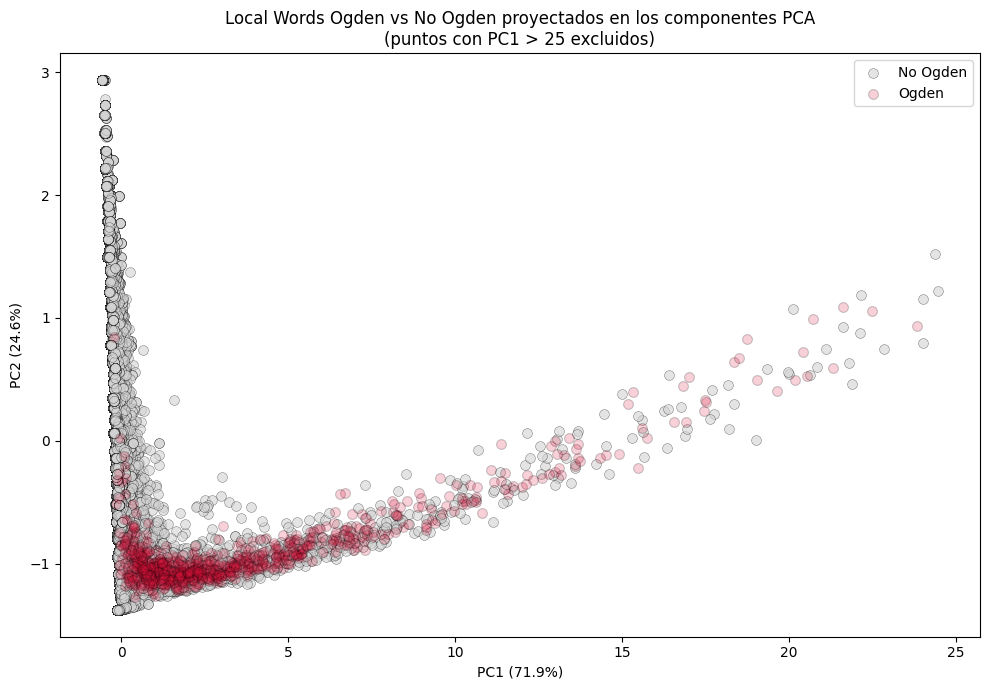

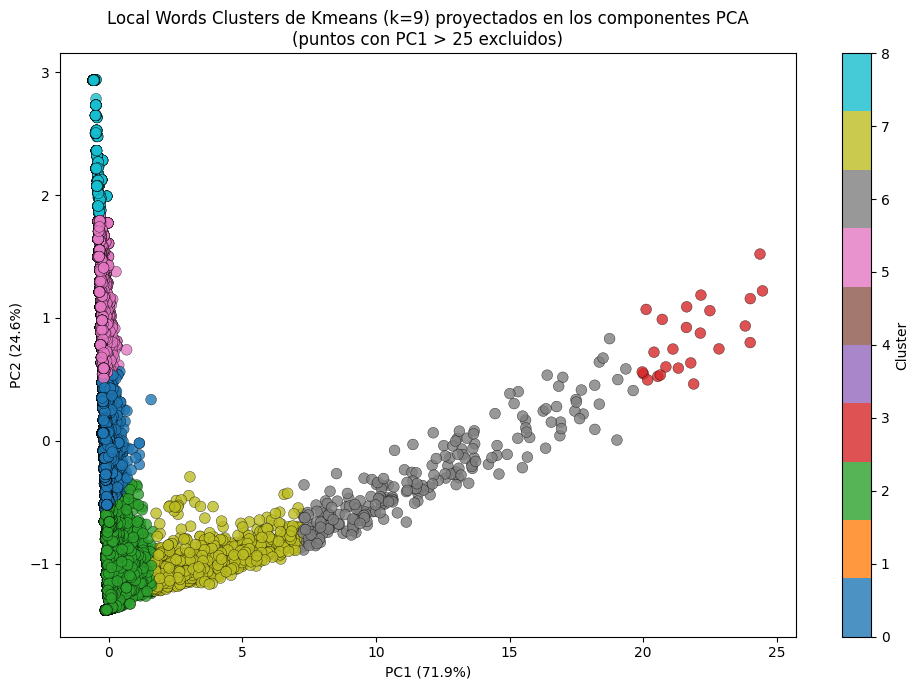

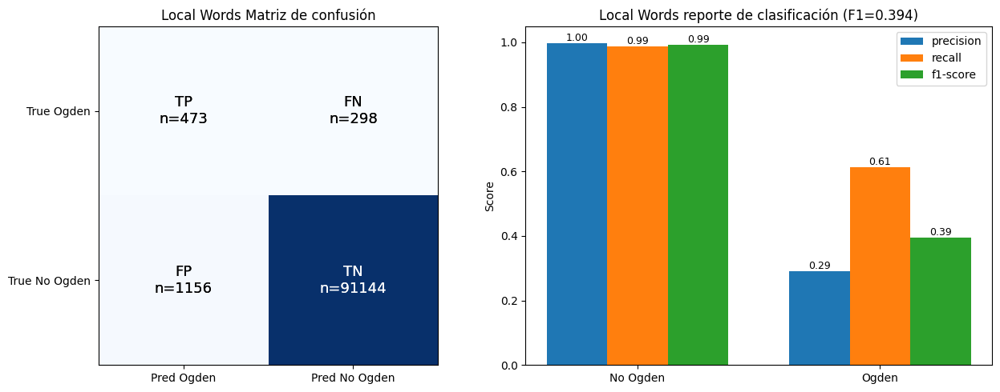

In [88]:
best_k_local_words = 9

kmeans_local_words = kmeans_schedule(
    result_local_words["X_pca_2d"],
    result_local_words["df"],
    result_local_words["pca_2d"],
    result_local_words["word_index"],
    title="Local Words",
    best_k=best_k_local_words,
    output_dir="kmeans/local_words",
    show=False
)

## LOCAL ALL


=== ogden words ===
Nodes analyzed: 5709

Degree mean=12.326 median=7 stdev=43.919
Mean degree percentile: 83.5

Computing Louvain communities...
degree_mean_percentile: 99.82
degree_median_percentile: 99.58
eigenvector_mean_percentile: 97.08
eigenvector_median_percentile: 89.09
pagerank_mean_percentile: 99.83
pagerank_median_percentile: 99.57
k_core_mean_percentile: 97.18
k_core_median_percentile: 97.18
clustering_mean_percentile: 85.26
clustering_median_percentile: 84.76
triangles_mean_percentile: 99.55
triangles_median_percentile: 98.64
betweenness_mean_percentile: 99.82
betweenness_median_percentile: 99.31
average_neighbor_degree_mean_percentile: 35.02
average_neighbor_degree_median_percentile: 34.91
louvain_community_size_mean_percentile: 54.96
louvain_community_size_median_percentile: 54.96
degree_list: 37.48% of Ogden --- Ogden was 28.90% of the top 1000 words
eigenvector_list: 8.69% of Ogden --- Ogden was 6.70% of the top 1000 words
pagerank_list: 37.09% of Ogden --- Ogden was 

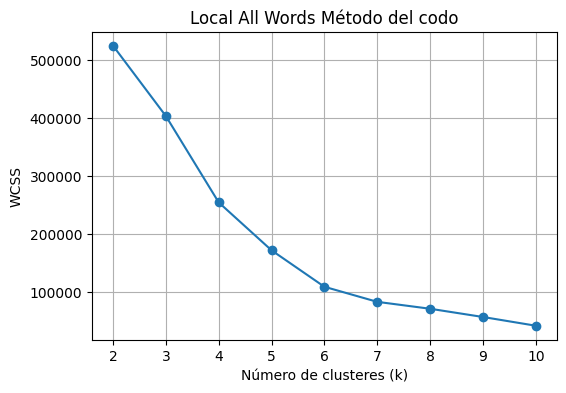

In [89]:
result_local_all = compare_ogden(final_local_db, mode="all", title="Local All Words")

'Before fixing, y=1 count: 571'

'After fixing, y=1 count: 4876'

'Best F1 score: 0.078'


 Ogden Counts:
Cluster 0: 4460
Cluster 1: 1
Cluster 2: 25
Cluster 3: 198
Cluster 4: 183
Cluster 5: 0
Cluster 6: 9

 Non Ogden Counts:
Cluster 0: 211781 - 2.06% of Ogden words in this cluster
Cluster 1: 3 - 25.00% of Ogden words in this cluster
Cluster 2: 48 - 34.25% of Ogden words in this cluster
Cluster 3: 13036 - 1.50% of Ogden words in this cluster
Cluster 4: 419 - 30.40% of Ogden words in this cluster
Cluster 5: 1559 - 0.00% of Ogden words in this cluster
Cluster 6: 6 - 60.00% of Ogden words in this cluster

Sample Ogden words from cluster 6: ['language', 'plant', 'people', 'make', 'genus', 'term', 'form', 'type', 'person', 'system']

Sample Ogden words from cluster 2: ['consist', 'element', 'area', 'base', 'body', 'food', 'state', 'name', 'speak', 'letter']

Sample Ogden words from cluster 4: ['r_bn:00020947n', 'distinct', 'may', 'medium', 'degree', 'national', 'context', 'philosophical', 'currency', 'item']

Sample Ogden words from cluster 1: ['use', 'know', 'also', 'one']


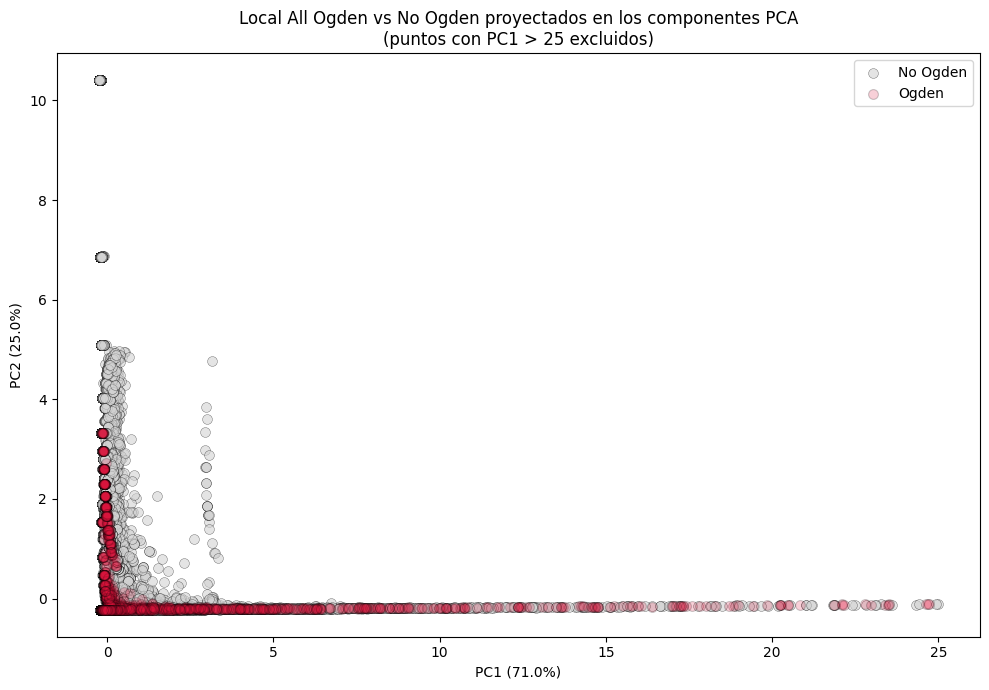

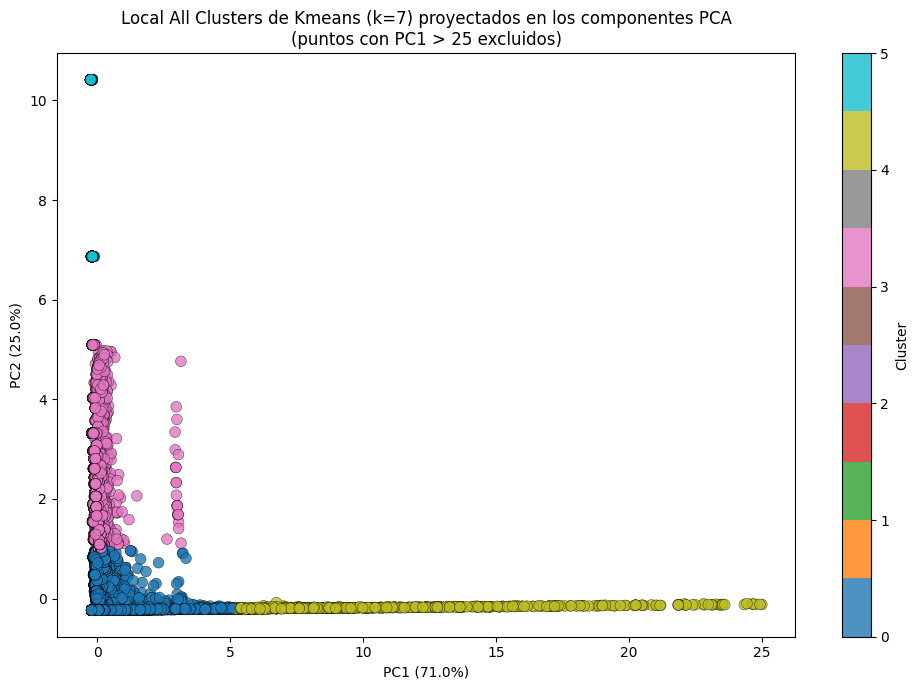

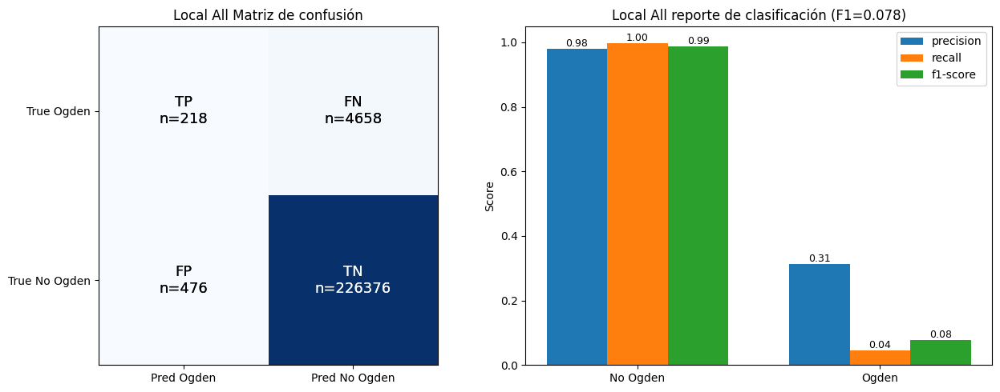

In [90]:
best_k_local_all = 7

fix_df_y_all(result_local_all["df"])

kmeans_local_all = kmeans_schedule(
    result_local_all["X_pca_2d"],
    result_local_all["df"],
    result_local_all["pca_2d"],
    result_local_all["word_index"],
    title="Local All",
    best_k=best_k_local_all,
    output_dir="kmeans/local_all",
    show=False
)

# AI MODELS

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

def random_tree(df, title):


    # ---------------------------------------------------------
    # 1. Prepare X and y
    # ---------------------------------------------------------
    df_model = df.copy()

    y = df_model.pop("y")
    for col in ["word", "pca1", "pca2", "cluster"]:
        if col in df_model.columns:
            df_model.pop(col)

    X = df_model  # remaining columns = features

    # ---------------------------------------------------------
    # 2. Train/test split
    # ---------------------------------------------------------
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # ---------------------------------------------------------
    # 3. Fit RandomForest
    # ---------------------------------------------------------
    rf = RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        class_weight="balanced",  # helps if y is imbalanced (e.g. Ogden vs non-Ogden)
        random_state=2026,
        n_jobs=-1
    )
    rf.fit(X_train, y_train)

    # ---------------------------------------------------------
    # 4. Predict + classification report
    # ---------------------------------------------------------
    y_pred = rf.predict(X_test)

    f1_score = classification_report(y_test, y_pred, target_names=["Non-Ogden", "Ogden"], output_dict=True)["Ogden"]["f1-score"]

    plot_classification_report(y_true=y_test, y_pred=y_pred, report=classification_report(y_test, y_pred, target_names=["No Ogden", "Ogden"], output_dict=True),
                                f1_score=f1_score, title=f"{title} - Random Forest", output_dir="random_forest")


    # ---------------------------------------------------------
    # 5. Feature importances
    # ---------------------------------------------------------
    importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
    print("\nTop features:\n", importances.head(15))

    return rf




Top features:
 pagerank       0.481425
degree         0.294344
betweenness    0.175967
clustering     0.048264
dtype: float64

Top features:
 betweenness    0.367708
pagerank       0.338248
degree         0.261268
clustering     0.032777
dtype: float64

Top features:
 pagerank       0.475367
degree         0.297686
betweenness    0.179941
clustering     0.047007
dtype: float64

Top features:
 betweenness    0.428131
pagerank       0.269632
degree         0.257322
clustering     0.044914
dtype: float64


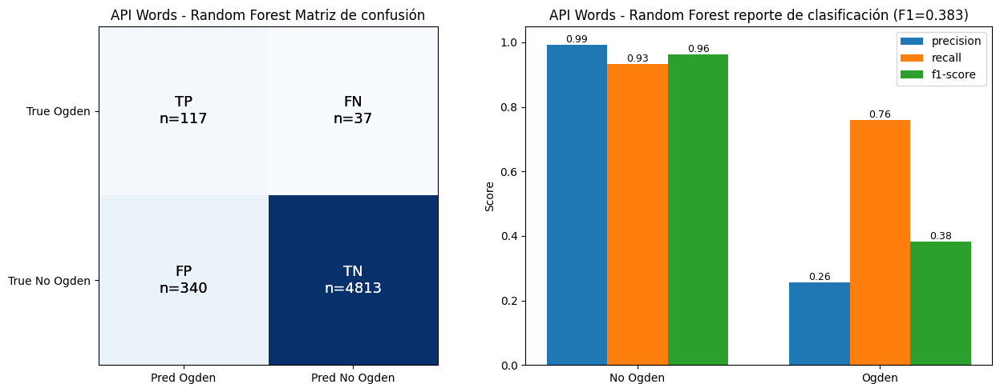

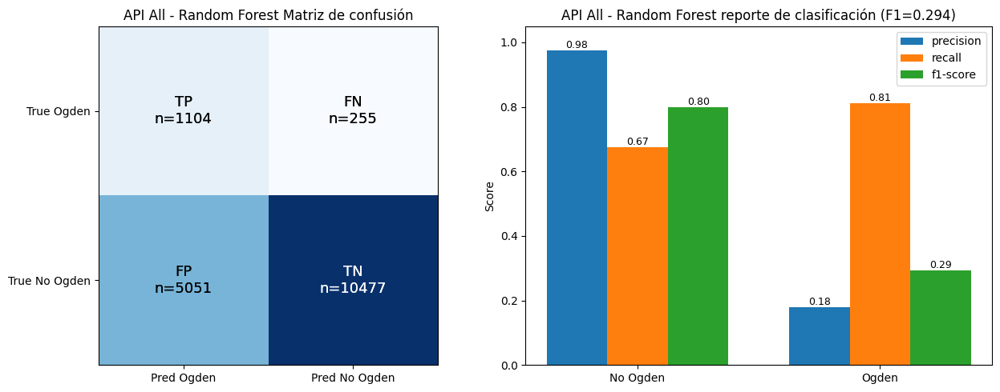

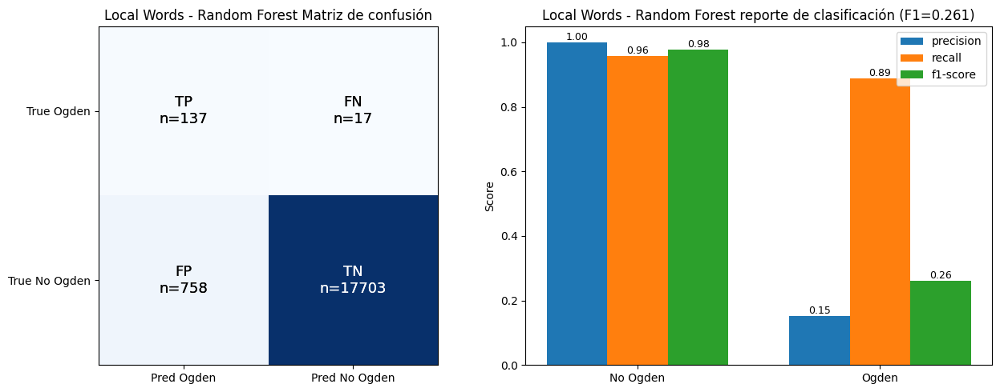

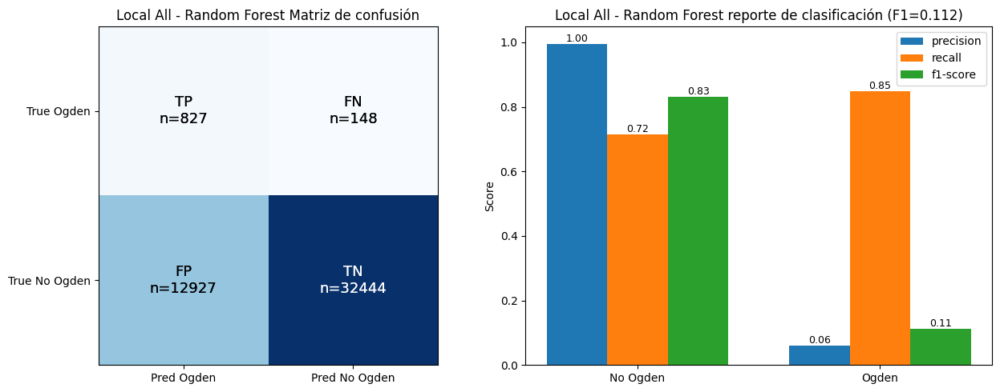

In [20]:
rf_api_words = random_tree(result_api_words["df"], title="API Words")
rf_api_all = random_tree(result_api_all["df"], title="API All")
rf_local_words = random_tree(result_local_words["df"], title="Local Words")
rf_local_all = random_tree(result_local_all["df"], title="Local All")


In [21]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_sample_weight
import pandas as pd

def gradient_boosting(df, title):

    # ---------------------------------------------------------
    # 1. Prepare X and y
    # ---------------------------------------------------------
    df_model = df.copy()

    y = df_model.pop("y")
    for col in ["word", "pca1", "pca2", "cluster"]:
        if col in df_model.columns:
            df_model.pop(col)

    X = df_model  # remaining columns = features

    # ---------------------------------------------------------
    # 2. Train/test split
    # ---------------------------------------------------------
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    # ---------------------------------------------------------
    # 3. Fit Gradient Boosting
    # ---------------------------------------------------------
    sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_train
    )



    gb = GradientBoostingClassifier(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=7,
        random_state=2026
    )

    gb.fit(X_train, y_train, sample_weight=sample_weights)

    # ---------------------------------------------------------
    # 4. Predict + classification report
    # ---------------------------------------------------------
    y_pred = gb.predict(X_test)

    f1_score = classification_report(y_test, y_pred, target_names=["Non-Ogden", "Ogden"], output_dict=True)["Ogden"]["f1-score"]

    plot_classification_report(y_true=y_test, y_pred=y_pred, report=classification_report(y_test, y_pred, target_names=["No Ogden", "Ogden"], output_dict=True),
                                f1_score=f1_score, title=f"{title} - Gradient Boosting", output_dir="gradient_boosting")

    # ---------------------------------------------------------
    # 5. Feature importances
    # ---------------------------------------------------------
    importances = pd.Series(
        gb.feature_importances_,
        index=X.columns
    ).sort_values(ascending=False)

    print("\nTop features:\n", importances.head(15))
    return gb


Top features:
 betweenness    0.469142
pagerank       0.354746
degree         0.146530
clustering     0.029582
dtype: float64

Top features:
 pagerank       0.812157
betweenness    0.074519
clustering     0.071814
degree         0.041511
dtype: float64

Top features:
 betweenness    0.548530
pagerank       0.276486
degree         0.129546
clustering     0.045437
dtype: float64

Top features:
 pagerank       0.866959
clustering     0.057772
betweenness    0.050224
degree         0.025045
dtype: float64


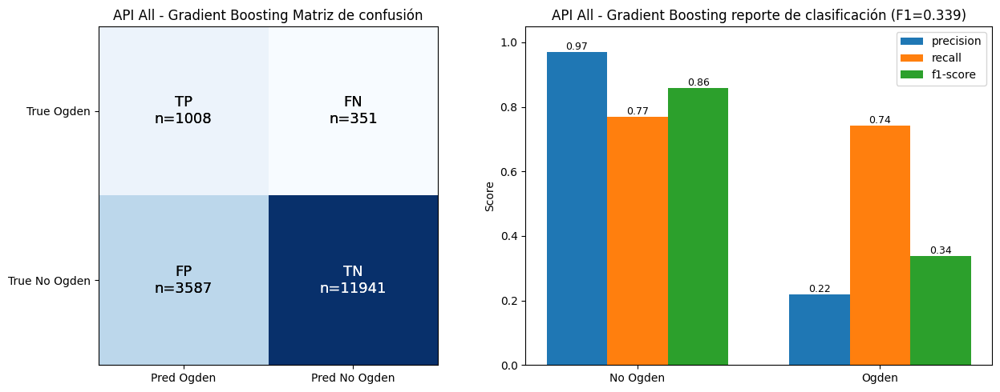

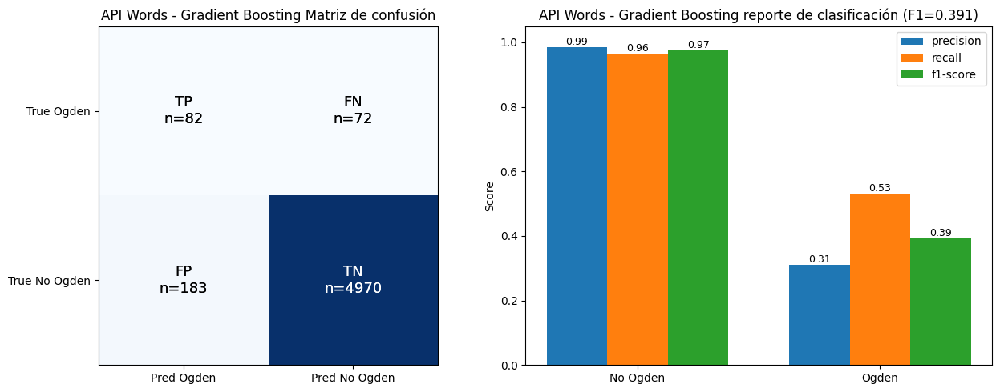

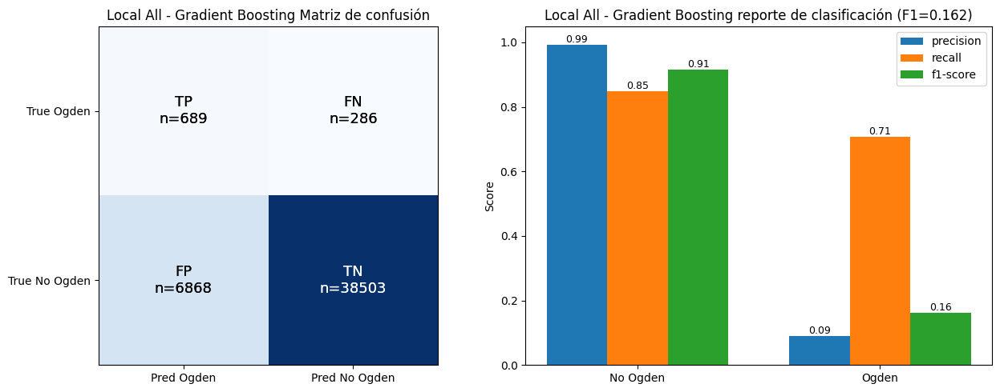

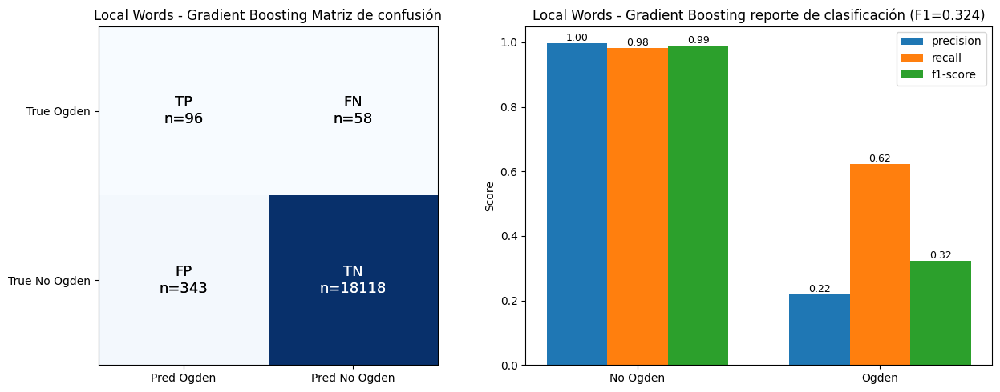

In [22]:
gb_api_all = gradient_boosting(result_api_all["df"], title="API All")
gb_api_words = gradient_boosting(result_api_words["df"], title="API Words")
gb_local_all = gradient_boosting(result_local_all["df"], title="Local All")
gb_local_words = gradient_boosting(result_local_words["df"], title="Local Words")

# General Analysis


In [25]:
def extract_table_data(concept_stats):
    table_1 = []
    table_2 = []
    table_3 = []


    table_1.append({
        "Nodos": concept_stats["nodes"],
        "Aristas": concept_stats["edges"],
        "Densidad": concept_stats["density"],
        "Grado prom.": concept_stats["avg_degree"],
        "Grado med.": concept_stats["median_degree"],
        "Grado máx.": concept_stats["max_degree"],
        "Nodo grado máx.": concept_stats["max_degree_node"]["label"],
        "Clustering prom.": concept_stats["avg_clustering_coefficient"],
    })

    table_2.append({
        "Comp.": concept_stats["num_components"],
        "% Comp. gigante": concept_stats["giant_component_fraction"],
        "Cam. prom.": concept_stats["avg_shortest_path_giant_component"],
        "Diám. est.": concept_stats["diameter_giant_component_est"],

        "PageRank top":
            f"{concept_stats['top_pagerank_nodes'][0]['label']} "
            f"({concept_stats['top_pagerank_nodes'][0]['pagerank']:.5f})",

        "Betweenness top":
            f"{concept_stats['top_betweenness_nodes'][0]['label']} "
            f"({concept_stats['top_betweenness_nodes'][0]['betweenness']:.5f})",

        "Closeness top":
            f"{concept_stats['top_closeness_nodes'][0]['label']} "
            f"({concept_stats['top_closeness_nodes'][0]['closeness']:.5f})",

        "Asortatividad": concept_stats["degree_assortativity"],
    })

    table_3.append({
        "N.º comunidades": concept_stats["louvain_num_communities"],
        "Modularidad": concept_stats["louvain_modularity"],
        "Tamaño comunidad mayor": max(concept_stats["louvain_community_sizes"]),
    })

    return table_1, table_2, table_3

In [26]:
def general_analysis(db_file, mode, language=None):
    print(f"\nAnalyzing database: {db_file.name}")
    conn = sqlite3.connect(db_file)
    conn.row_factory = sqlite3.Row
    G = g.build_graph(conn, mode=mode, language=language)
    #full_stats = gs.graph_connectivity_stats(nodes, edges, adjacency, label="full graph (with hubs)")
    #gs.print_stats(full_stats)

    concept_stats = gs.graph_connectivity_stats(
        G, label="concept-only graph (no hubs)"
    )
    gs.print_stats(concept_stats)
    extracted_tables = extract_table_data(concept_stats)
    for table in extracted_tables:
        df = pd.DataFrame(table)
        print(df.to_string(index=False))


In [27]:
general_analysis(final_api_db, mode="words")


Analyzing database: api_database.db
--- concept-only graph (no hubs) ---
nodes                              : 46407
edges                              : 403899
density                            : 0.000375
avg_degree                         : 17.407
median_degree                      : 9
max_degree                         : 2052
max_degree_node                    : {'id': 'somethingEN', 'label': 'something', 'type': 'word', 'degree': 2052}
isolated_nodes                     : 0
num_components                     : 2
giant_component_size               : 46405
giant_component_fraction           : 1.0
avg_shortest_path_giant_component  : 3.776
diameter_giant_component_est       : 9
avg_clustering_coefficient         : 0.0927
top_pagerank_nodes                 : [{'id': 'somethingEN', 'label': 'something', 'type': 'word', 'pagerank': 0.001972}, {'id': 'makeEN', 'label': 'make', 'type': 'word', 'pagerank': 0.001907}, {'id': 'useEN', 'label': 'use', 'type': 'word', 'pagerank': 0.001888}, {'

In [28]:
general_analysis(final_api_db, mode="words", language="EN")


Analyzing database: api_database.db
--- concept-only graph (no hubs) ---
nodes                              : 26534
edges                              : 217681
density                            : 0.000618
avg_degree                         : 16.408
median_degree                      : 6.0
max_degree                         : 2052
max_degree_node                    : {'id': 'somethingEN', 'label': 'something', 'type': 'word', 'degree': 2052}
isolated_nodes                     : 0
num_components                     : 2
giant_component_size               : 26531
giant_component_fraction           : 0.9999
avg_shortest_path_giant_component  : 3.363
diameter_giant_component_est       : 9
avg_clustering_coefficient         : 0.1232
top_pagerank_nodes                 : [{'id': 'somethingEN', 'label': 'something', 'type': 'word', 'pagerank': 0.003925}, {'id': 'makeEN', 'label': 'make', 'type': 'word', 'pagerank': 0.00368}, {'id': 'useEN', 'label': 'use', 'type': 'word', 'pagerank': 0.003573}

In [29]:
general_analysis(final_api_db, mode="words", language="ES")


Analyzing database: api_database.db
--- concept-only graph (no hubs) ---
nodes                              : 19872
edges                              : 118195
density                            : 0.000599
avg_degree                         : 11.896
median_degree                      : 6.0
max_degree                         : 1197
max_degree_node                    : {'id': 'personaES', 'label': 'persona', 'type': 'word', 'degree': 1197}
isolated_nodes                     : 0
num_components                     : 15
giant_component_size               : 19828
giant_component_fraction           : 0.9978
avg_shortest_path_giant_component  : 3.801
diameter_giant_component_est       : 9
avg_clustering_coefficient         : 0.1192
top_pagerank_nodes                 : [{'id': 'personaES', 'label': 'persona', 'type': 'word', 'pagerank': 0.004543}, {'id': 'hacerES', 'label': 'hacer', 'type': 'word', 'pagerank': 0.003213}, {'id': 'alguienES', 'label': 'alguien', 'type': 'word', 'pagerank': 0.002

In [30]:
general_analysis(final_api_db, mode="all")


Analyzing database: api_database.db
--- concept-only graph (no hubs) ---
nodes                              : 130628
edges                              : 514044
density                            : 6e-05
avg_degree                         : 7.87
median_degree                      : 5.0
max_degree                         : 2529
max_degree_node                    : {'id': 'something', 'label': 'something', 'type': 'concept', 'degree': 2529}
isolated_nodes                     : 0
num_components                     : 2
giant_component_size               : 130625
giant_component_fraction           : 1.0
avg_shortest_path_giant_component  : 5.105
diameter_giant_component_est       : 12
avg_clustering_coefficient         : 0.024
top_pagerank_nodes                 : [{'id': 'something', 'label': 'something', 'type': 'concept', 'pagerank': 0.001862}, {'id': 'make', 'label': 'make', 'type': 'concept', 'pagerank': 0.00172}, {'id': 'use', 'label': 'use', 'type': 'concept', 'pagerank': 0.001558}, 

In [31]:
general_analysis(final_api_db, mode="all", language="EN")


Analyzing database: api_database.db
--- concept-only graph (no hubs) ---
nodes                              : 84433
edges                              : 292625
density                            : 8.2e-05
avg_degree                         : 6.932
median_degree                      : 4
max_degree                         : 2529
max_degree_node                    : {'id': 'something', 'label': 'something', 'type': 'concept', 'degree': 2529}
isolated_nodes                     : 0
num_components                     : 3
giant_component_size               : 84426
giant_component_fraction           : 0.9999
avg_shortest_path_giant_component  : 4.865
diameter_giant_component_est       : 11
avg_clustering_coefficient         : 0.0148
top_pagerank_nodes                 : [{'id': 'something', 'label': 'something', 'type': 'concept', 'pagerank': 0.003408}, {'id': 'make', 'label': 'make', 'type': 'concept', 'pagerank': 0.003088}, {'id': 'use', 'label': 'use', 'type': 'concept', 'pagerank': 0.00271

In [32]:
general_analysis(final_api_db, mode="all", language="ES")


Analyzing database: api_database.db
--- concept-only graph (no hubs) ---
nodes                              : 49012
edges                              : 151128
density                            : 0.000126
avg_degree                         : 6.167
median_degree                      : 4.0
max_degree                         : 1323
max_degree_node                    : {'id': 'persona', 'label': 'persona', 'type': 'concept', 'degree': 1323}
isolated_nodes                     : 0
num_components                     : 20
giant_component_size               : 48912
giant_component_fraction           : 0.998
avg_shortest_path_giant_component  : 5.32
diameter_giant_component_est       : 16
avg_clustering_coefficient         : 0.0039
top_pagerank_nodes                 : [{'id': 'persona', 'label': 'persona', 'type': 'concept', 'pagerank': 0.003555}, {'id': 'hacer', 'label': 'hacer', 'type': 'concept', 'pagerank': 0.002809}, {'id': 'alguien', 'label': 'alguien', 'type': 'concept', 'pagerank': 0.0

In [33]:
general_analysis(final_local_db, mode="words")


Analyzing database: local_database.db
--- concept-only graph (no hubs) ---
nodes                              : 155150
edges                              : 1883545
density                            : 0.000156
avg_degree                         : 24.28
median_degree                      : 14.0
max_degree                         : 8677
max_degree_node                    : {'id': 'useEN', 'label': 'use', 'type': 'word', 'degree': 8677}
isolated_nodes                     : 5
num_components                     : 11
giant_component_size               : 155127
giant_component_fraction           : 0.9999
avg_shortest_path_giant_component  : 3.568
diameter_giant_component_est       : 8
avg_clustering_coefficient         : 0.2648
top_pagerank_nodes                 : [{'id': 'useEN', 'label': 'use', 'type': 'word', 'pagerank': 0.001831}, {'id': 'alsoEN', 'label': 'also', 'type': 'word', 'pagerank': 0.00171}, {'id': 'knowEN', 'label': 'know', 'type': 'word', 'pagerank': 0.001521}, {'id': 'oneEN'

In [34]:
general_analysis(final_local_db, mode="words", language="EN")


Analyzing database: local_database.db
--- concept-only graph (no hubs) ---
nodes                              : 93071
edges                              : 932582
density                            : 0.000215
avg_degree                         : 20.04
median_degree                      : 10
max_degree                         : 8670
max_degree_node                    : {'id': 'useEN', 'label': 'use', 'type': 'word', 'degree': 8670}
isolated_nodes                     : 11
num_components                     : 26
giant_component_size               : 92998
giant_component_fraction           : 0.9992
avg_shortest_path_giant_component  : 3.244
diameter_giant_component_est       : 8
avg_clustering_coefficient         : 0.3163
top_pagerank_nodes                 : [{'id': 'useEN', 'label': 'use', 'type': 'word', 'pagerank': 0.003808}, {'id': 'alsoEN', 'label': 'also', 'type': 'word', 'pagerank': 0.003625}, {'id': 'knowEN', 'label': 'know', 'type': 'word', 'pagerank': 0.003254}, {'id': 'oneEN', '

In [35]:
general_analysis(final_local_db, mode="words", language="ES")


Analyzing database: local_database.db
--- concept-only graph (no hubs) ---
nodes                              : 62073
edges                              : 597671
density                            : 0.00031
avg_degree                         : 19.257
median_degree                      : 10
max_degree                         : 4904
max_degree_node                    : {'id': 'familiaES', 'label': 'familia', 'type': 'word', 'degree': 4904}
isolated_nodes                     : 12
num_components                     : 45
giant_component_size               : 61933
giant_component_fraction           : 0.9977
avg_shortest_path_giant_component  : 3.424
diameter_giant_component_est       : 8
avg_clustering_coefficient         : 0.2878
top_pagerank_nodes                 : [{'id': 'familiaES', 'label': 'familia', 'type': 'word', 'pagerank': 0.003842}, {'id': 'géneroES', 'label': 'género', 'type': 'word', 'pagerank': 0.002936}, {'id': 'especieES', 'label': 'especie', 'type': 'word', 'pagerank': 0.

In [36]:
general_analysis(final_local_db, mode="all")


Analyzing database: local_database.db
--- concept-only graph (no hubs) ---
nodes                              : 346252
edges                              : 2137278
density                            : 3.6e-05
avg_degree                         : 12.345
median_degree                      : 6.0
max_degree                         : 9340
max_degree_node                    : {'id': 'use', 'label': 'use', 'type': 'concept', 'degree': 9340}
isolated_nodes                     : 0
num_components                     : 23
giant_component_size               : 346184
giant_component_fraction           : 0.9998
avg_shortest_path_giant_component  : 4.773
diameter_giant_component_est       : 11
avg_clustering_coefficient         : 0.0983
top_pagerank_nodes                 : [{'id': 'use', 'label': 'use', 'type': 'concept', 'pagerank': 0.001794}, {'id': 'also', 'label': 'also', 'type': 'concept', 'pagerank': 0.001667}, {'id': 'know', 'label': 'know', 'type': 'concept', 'pagerank': 0.001459}, {'id': 'o

In [37]:
general_analysis(final_local_db, mode="all", language="EN")


Analyzing database: local_database.db
--- concept-only graph (no hubs) ---
nodes                              : 231728
edges                              : 1114360
density                            : 4.2e-05
avg_degree                         : 9.618
median_degree                      : 5.0
max_degree                         : 9340
max_degree_node                    : {'id': 'use', 'label': 'use', 'type': 'concept', 'degree': 9340}
isolated_nodes                     : 0
num_components                     : 48
giant_component_size               : 231472
giant_component_fraction           : 0.9989
avg_shortest_path_giant_component  : 4.786
diameter_giant_component_est       : 14
avg_clustering_coefficient         : 0.0327
top_pagerank_nodes                 : [{'id': 'also', 'label': 'also', 'type': 'concept', 'pagerank': 0.003068}, {'id': 'use', 'label': 'use', 'type': 'concept', 'pagerank': 0.003016}, {'id': 'know', 'label': 'know', 'type': 'concept', 'pagerank': 0.002755}, {'id': 'fa

In [38]:
general_analysis(final_local_db, mode="all", language="ES")


Analyzing database: local_database.db
--- concept-only graph (no hubs) ---
nodes                              : 135585
edges                              : 692951
density                            : 7.5e-05
avg_degree                         : 10.222
median_degree                      : 5
max_degree                         : 4960
max_degree_node                    : {'id': 'familia', 'label': 'familia', 'type': 'concept', 'degree': 4960}
isolated_nodes                     : 0
num_components                     : 49
giant_component_size               : 135271
giant_component_fraction           : 0.9977
avg_shortest_path_giant_component  : 4.802
diameter_giant_component_est       : 12
avg_clustering_coefficient         : 0.0523
top_pagerank_nodes                 : [{'id': 'familia', 'label': 'familia', 'type': 'concept', 'pagerank': 0.003521}, {'id': 'género', 'label': 'género', 'type': 'concept', 'pagerank': 0.00273}, {'id': 'especie', 'label': 'especie', 'type': 'concept', 'pagerank'

# PLOT SERIES

In [39]:

api_files = list(Path(API_DBS_PATH).glob("*"))
for api_file in api_files:
    print(f"Found API database file: {api_file.name}")

local_files = list(Path(LOCAL_DBS_PATH).glob("*.db"))
for local_file in local_files:
    print(f"Found Local database file: {local_file.name}")


Found API database file: 20260713_183720_cycle_1_start.txt
Found API database file: 20260714_032935_cycle_1.db
Found API database file: 20260714_043840_cycle_2.db
Found API database file: 20260714_232034_cycle_3_start.txt
Found API database file: 20260715_072131_cycle_3.db
Found API database file: 20260716_042930_cycle_4_start.txt
Found API database file: 20260716_101344_cycle_4.db
Found API database file: 20260716_150606_cycle_5.db
Found API database file: 20260717_113438_cycle_6_start.txt
Found API database file: 20260717_183130_cycle_6.db
Found API database file: 20260718_052342_cycle_7.db
Found Local database file: 20260714_050552_database_backup_0_local_ogden_cycle.db
Found Local database file: 20260714_091557_database_backup_1_local_cycle.db
Found Local database file: 20260714_151445_database_backup_2_local_cycle.db
Found Local database file: 20260714_183833_database_backup_3_local_cycle.db
Found Local database file: 20260714_195857_database_backup_4_local_cycle.db
Found Local da

In [40]:
from datetime import datetime

def plot_series(title, output_dir, db_files, mode="all", language=None):
    stats_list = {}
    intervals = []
    timestamps = []
    cicle_start = None
    cicle_end = None
    for db_file in db_files:
        if "local" not in db_file.name:
            if "start" in db_file.name:
                cicle_start = datetime.strptime(db_file.name[:15], "%Y%m%d_%H%M%S")
            else:
                cicle_end = datetime.strptime(db_file.name[:15], "%Y%m%d_%H%M%S")
                if cicle_start is None:
                    raise ValueError(f"Found cicle_end without a corresponding cicle_start for file: {db_file.name}")
                interval = (cicle_end - cicle_start).total_seconds() / 60
                intervals.append(interval)
                cicle_start = cicle_end
                cicle_end = None

        else:
            timestamps.append(datetime.strptime(db_file.name[:15], "%Y%m%d_%H%M%S"))
        if not db_file.name.endswith(".db"):
            continue
        conn = sqlite3.connect(db_file)
        print(f"\nAnalyzing database: {db_file.name}")
        conn.row_factory = sqlite3.Row
        G = g.build_graph(conn, mode=mode, language=language)
        full_stats = gs.graph_connectivity_stats(G, label=f"{title} grafo (con hubs)")
        for stat_name, stat_value in full_stats.items():
            stats_list.setdefault(stat_name, []).append(stat_value)
        print(stats_list)
    gs.plot_stats_series(stats_list, output_dir, title, show=False)

    if len(intervals) == 0:
        intervals = [
            (timestamps[i] - timestamps[i - 1]).total_seconds() / 60
            for i in range(1, len(timestamps))
        ]

    # Plot
    plt.figure(figsize=(10, 4))
    plt.plot(range(1, len(intervals)+1), intervals, marker='o')
    plt.title(f"{title } Intervalo entre ciclos")
    plt.xlabel("Ciclos")
    plt.ylabel("Intervalo (minutos)")
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()





Analyzing database: 20260714_032935_cycle_1.db
{'label': ['API Words grafo (con hubs)'], 'nodes': [18510], 'edges': [123463], 'density': [0.000721], 'avg_degree': [13.34], 'median_degree': [7.0], 'max_degree': [755], 'max_degree_node': [{'id': 'makeEN', 'label': 'make', 'type': 'word', 'degree': 755}], 'top_degree_nodes': [[{'id': 'makeEN', 'label': 'make', 'type': 'word', 'degree': 755}, {'id': 'useEN', 'label': 'use', 'type': 'word', 'degree': 653}, {'id': 'somethingEN', 'label': 'something', 'type': 'word', 'degree': 624}, {'id': 'actEN', 'label': 'act', 'type': 'word', 'degree': 512}, {'id': 'personEN', 'label': 'person', 'type': 'word', 'degree': 412}]], 'isolated_nodes': [0], 'num_components': [1], 'giant_component_size': [18510], 'giant_component_fraction': [1.0], 'avg_shortest_path_giant_component': [3.81], 'diameter_giant_component_est': [9], 'diameter_path_labels': [['malestar', 'pesadumbre', 'hacer', 'act', 'buss', 'lip', 'gastropod', 'Mollusca', 'Mollusca', 'gastrópodo']],

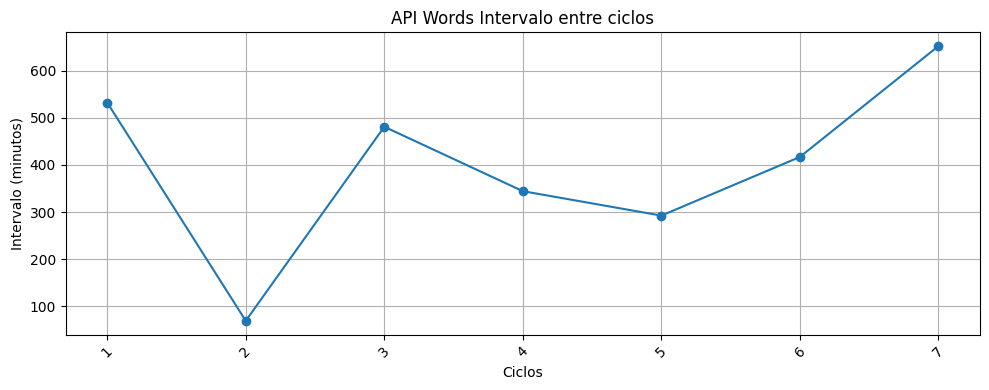

In [41]:
plot_series(title="API Words", output_dir="api", db_files=api_files, mode="words")


Analyzing database: 20260714_032935_cycle_1.db
{'label': ['API All grafo (con hubs)'], 'nodes': [43964], 'edges': [157291], 'density': [0.000163], 'avg_degree': [7.155], 'median_degree': [5.0], 'max_degree': [808], 'max_degree_node': [{'id': 'something', 'label': 'something', 'type': 'concept', 'degree': 808}], 'top_degree_nodes': [[{'id': 'something', 'label': 'something', 'type': 'concept', 'degree': 808}, {'id': 'make', 'label': 'make', 'type': 'concept', 'degree': 745}, {'id': 'use', 'label': 'use', 'type': 'concept', 'degree': 706}, {'id': 'act', 'label': 'act', 'type': 'concept', 'degree': 508}, {'id': 'one', 'label': 'one', 'type': 'concept', 'degree': 470}]], 'isolated_nodes': [0], 'num_components': [1], 'giant_component_size': [43964], 'giant_component_fraction': [1.0], 'avg_shortest_path_giant_component': [5.35], 'diameter_giant_component_est': [12], 'diameter_path_labels': [['señorita', 'señorita_bn:00034453n', 'mujer', 'nene_bn:00007631n', 'hombre', 'sistema_bn:00075760n',

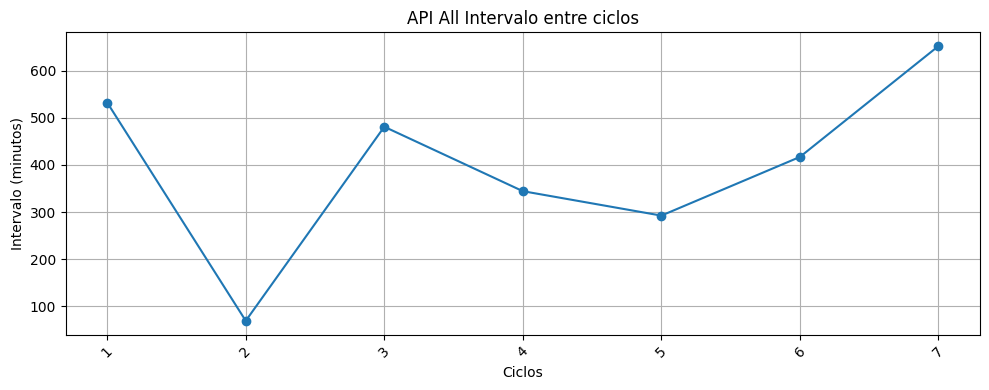

In [42]:
plot_series(title="API All", output_dir="api", db_files=api_files, mode="all")


Analyzing database: 20260714_050552_database_backup_0_local_ogden_cycle.db
{'label': ['Local Words grafo (con hubs)'], 'nodes': [21391], 'edges': [184474], 'density': [0.000806], 'avg_degree': [17.248], 'median_degree': [11], 'max_degree': [885], 'max_degree_node': [{'id': 'useEN', 'label': 'use', 'type': 'word', 'degree': 885}], 'top_degree_nodes': [[{'id': 'useEN', 'label': 'use', 'type': 'word', 'degree': 885}, {'id': 'oneEN', 'label': 'one', 'type': 'word', 'degree': 648}, {'id': 'alsoEN', 'label': 'also', 'type': 'word', 'degree': 646}, {'id': 'knowEN', 'label': 'know', 'type': 'word', 'degree': 520}, {'id': 'systemEN', 'label': 'system', 'type': 'word', 'degree': 461}]], 'isolated_nodes': [0], 'num_components': [1], 'giant_component_size': [21391], 'giant_component_fraction': [1.0], 'avg_shortest_path_giant_component': [3.775], 'diameter_giant_component_est': [8], 'diameter_path_labels': [['apellido', 'littlir', 'little', 'short', 'paracortir', 'base', 'letra', 'ص', 'decimocuart

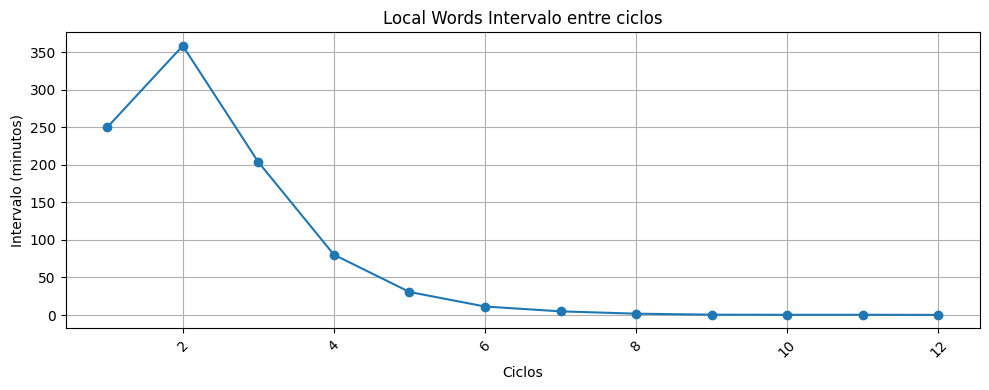

In [43]:
plot_series(title="Local Words", output_dir="local", db_files=local_files, mode="words")


Analyzing database: 20260714_050552_database_backup_0_local_ogden_cycle.db
{'label': ['Local All grafo (con hubs)'], 'nodes': [40990], 'edges': [211103], 'density': [0.000251], 'avg_degree': [10.3], 'median_degree': [6.0], 'max_degree': [956], 'max_degree_node': [{'id': 'use', 'label': 'use', 'type': 'concept', 'degree': 956}], 'top_degree_nodes': [[{'id': 'use', 'label': 'use', 'type': 'concept', 'degree': 956}, {'id': 'one', 'label': 'one', 'type': 'concept', 'degree': 684}, {'id': 'also', 'label': 'also', 'type': 'concept', 'degree': 665}, {'id': 'know', 'label': 'know', 'type': 'concept', 'degree': 510}, {'id': 'animal', 'label': 'animal', 'type': 'concept', 'degree': 490}]], 'isolated_nodes': [0], 'num_components': [1], 'giant_component_size': [40990], 'giant_component_fraction': [1.0], 'avg_shortest_path_giant_component': [5.042], 'diameter_giant_component_est': [11], 'diameter_path_labels': [['terminología', 'opir_bn:00059063n', 'abierto', 'arco_bn:00005387n', 'forma', 'mar_bn:

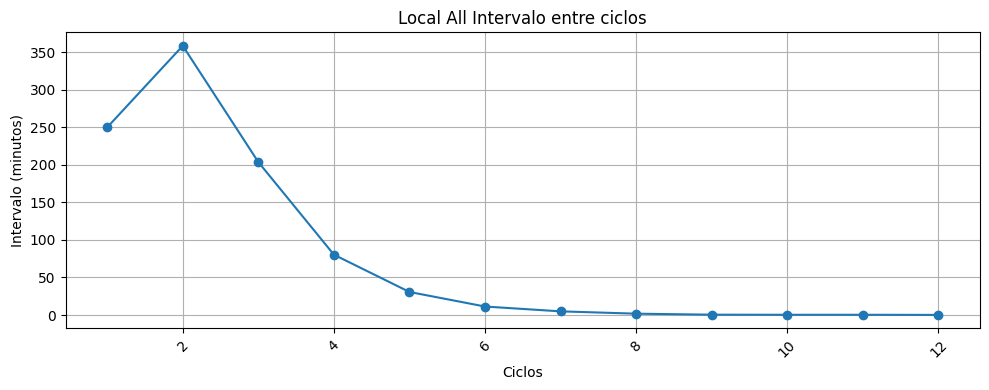

In [52]:
plot_series(title="Local All", output_dir="local", db_files=local_files, mode="all")

# Utilizando Modelos para predecir Ogden en Espanol


In [91]:
def get_spanish_X(db_file, scaler, pca_2d, mode="words"):

    conn = sqlite3.connect(db_file)
    conn.row_factory = sqlite3.Row

    G = g.build_graph(conn, mode=mode, language="ES")
    results = wga.core_word_metrics(G, [], mode=mode, language="ES")
            
    X = []
    #print(results["node_metrics"].keys())
    for word in G.nodes():
        row = [
            results["node_metrics"][word][feature]
            for feature in FEATURES
        ]
        X.append(row)

    X_scaled = scaler.transform(X)

    df = pd.DataFrame(X_scaled, columns=FEATURES)
    if mode == "words":
        df["word"] = [word[0][:-2] for word in results["summary"]["degree_list_unsorted"]]
    elif mode == "all":
        df["word"] = [word[0] for word in results["summary"]["degree_list_unsorted"]]

    return_dict = {
        "X": X_scaled,
        "X_pca_2d": pca_2d.transform(X_scaled),
        "df": df,
        "node_metrics": results["node_metrics"],
        "summary": results["summary"]
    }

    return return_dict

In [98]:
def predict_spanish(X, model, title):
    df = pd.DataFrame(X)

    y_pred = model.predict(df)
    df["predicted_y"] = y_pred

    ogden_count = (df["predicted_y"] == 1).sum()
    total_count = len(df)

    #print(f"{title} - Predicted Ogden words: {ogden_count}/{total_count} ({ogden_count/total_count*100:.2f}%)")

    return df

In [94]:
ES_api_words = get_spanish_X(final_api_db, result_api_words["scaler"], result_api_words["pca_2d"], mode="words")
ES_api_all = get_spanish_X(final_api_db, result_api_all["scaler"], result_api_all["pca_2d"], mode="all")
ES_local_words = get_spanish_X(final_local_db, result_local_words["scaler"], result_local_words["pca_2d"], mode="words")
ES_local_all = get_spanish_X(final_local_db, result_local_all["scaler"], result_local_all["pca_2d"], mode="all")

Computing Louvain communities...
Computing Louvain communities...
Computing Louvain communities...
Computing Louvain communities...


In [99]:
df_api_words_kmeans = predict_spanish(ES_api_words["X_pca_2d"], kmeans_api_words, title="API Words - KMeans")
df_api_all_kmeans = predict_spanish(ES_api_all["X_pca_2d"], kmeans_api_all, title="API All - KMeans")
df_local_words_kmeans = predict_spanish(ES_local_words["X_pca_2d"], kmeans_local_words, title="Local Words - KMeans")
df_local_all_kmeans = predict_spanish(ES_local_all["X_pca_2d"], kmeans_local_all, title="Local All - KMeans")

In [100]:
df_api_words_kmeans["word"] = ES_api_words["df"]["word"]
df_api_all_kmeans["word"] = ES_api_all["df"]["word"]
df_local_words_kmeans["word"] = ES_local_words["df"]["word"]
df_local_all_kmeans["word"] = ES_local_all["df"]["word"]

In [101]:
df_api_words_rf = predict_spanish(ES_api_words["X"], rf_api_words, title="API Words - Random Forest")
df_api_all_rf = predict_spanish(ES_api_all["X"], rf_api_all, title="API All - Random Forest")
df_local_words_rf = predict_spanish(ES_local_words["X"], rf_local_words, title="Local Words - Random Forest")
df_local_all_rf = predict_spanish(ES_local_all["X"], rf_local_all, title="Local All - Random Forest")

C:\Users\André\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
C:\Users\André\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
C:\Users\André\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
C:\Users\André\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\b

In [102]:
df_api_words_rf["word"] = ES_api_words["df"]["word"]
df_api_all_rf["word"] = ES_api_all["df"]["word"]
df_local_words_rf["word"] = ES_local_words["df"]["word"]
df_local_all_rf["word"] = ES_local_all["df"]["word"]

In [103]:
df_api_words_gb = predict_spanish(ES_api_words["X"], gb_api_words, title="API Words - Gradient Boosting")
df_api_all_gb = predict_spanish(ES_api_all["X"], gb_api_all, title="API All - Gradient Boosting")
df_local_words_gb = predict_spanish(ES_local_words["X"], gb_local_words, title="Local Words - Gradient Boosting")   
df_local_all_gb = predict_spanish(ES_local_all["X"], gb_local_all, title="Local All - Gradient Boosting")

C:\Users\André\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
C:\Users\André\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
C:\Users\André\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
C:\Users\André\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packag

In [104]:
df_api_words_gb["word"] = ES_api_words["df"]["word"]
df_api_all_gb["word"] = ES_api_all["df"]["word"]
df_local_words_gb["word"] = ES_local_words["df"]["word"]
df_local_all_gb["word"] = ES_local_all["df"]["word"]

In [105]:
df_api_words_kmeans.to_csv("dfs/df_api_words_kmeans.csv", index=False)
df_api_all_kmeans.to_csv("dfs/df_api_all_kmeans.csv", index=False)
df_local_words_kmeans.to_csv("dfs/df_local_words_kmeans.csv", index=False)
df_local_all_kmeans.to_csv("dfs/df_local_all_kmeans.csv", index=False)

df_api_words_rf.to_csv("dfs/df_api_words_rf.csv", index=False)
df_api_all_rf.to_csv("dfs/df_api_all_rf.csv", index=False)
df_local_words_rf.to_csv("dfs/df_local_words_rf.csv", index=False)
df_local_all_rf.to_csv("dfs/df_local_all_rf.csv", index=False)

df_api_words_gb.to_csv("dfs/df_api_words_gb.csv", index=False)
df_api_all_gb.to_csv("dfs/df_api_all_gb.csv", index=False)
df_local_words_gb.to_csv("dfs/df_local_words_gb.csv", index=False)
df_local_all_gb.to_csv("dfs/df_local_all_gb.csv", index=False)

words_dfs = [df_api_words_kmeans, df_api_words_rf, df_api_words_gb,
             df_local_words_kmeans, df_local_words_rf, df_local_words_gb]

all_dfs = [df_api_all_kmeans, df_api_all_rf, df_api_all_gb,
            df_local_all_kmeans, df_local_all_rf, df_local_all_gb]

In [106]:
def print_number_ogden_predictions(df, name):
    ogden_count = (df["predicted_y"] == 1).sum()
    total_count = len(df)
    print(f"{name} - Predicted Ogden words: {ogden_count}/{total_count} ({ogden_count/total_count*100:.2f}%)")

print_number_ogden_predictions(df_api_all_kmeans, "API All - KMeans")
print_number_ogden_predictions(df_api_words_kmeans, "API Words - KMeans")
print_number_ogden_predictions(df_local_all_kmeans, "Local All - KMeans")
print_number_ogden_predictions(df_local_words_kmeans, "Local Words - KMeans")

print_number_ogden_predictions(df_api_all_rf, "API All - Random Forest")
print_number_ogden_predictions(df_api_words_rf, "API Words - Random Forest")
print_number_ogden_predictions(df_local_all_rf, "Local All - Random Forest")
print_number_ogden_predictions(df_local_words_rf, "Local Words - Random Forest")

print_number_ogden_predictions(df_api_all_gb, "API All - Gradient Boosting")
print_number_ogden_predictions(df_api_words_gb, "API Words - Gradient Boosting")
print_number_ogden_predictions(df_local_all_gb, "Local All - Gradient Boosting")
print_number_ogden_predictions(df_local_words_gb, "Local Words - Gradient Boosting")


API All - KMeans - Predicted Ogden words: 10/49012 (0.02%)
API Words - KMeans - Predicted Ogden words: 6/19872 (0.03%)
Local All - KMeans - Predicted Ogden words: 1/135585 (0.00%)
Local Words - KMeans - Predicted Ogden words: 14/62073 (0.02%)
API All - Random Forest - Predicted Ogden words: 3162/49012 (6.45%)
API Words - Random Forest - Predicted Ogden words: 758/19872 (3.81%)
Local All - Random Forest - Predicted Ogden words: 24443/135585 (18.03%)
Local Words - Random Forest - Predicted Ogden words: 2337/62073 (3.76%)
API All - Gradient Boosting - Predicted Ogden words: 536/49012 (1.09%)
API Words - Gradient Boosting - Predicted Ogden words: 136/19872 (0.68%)
Local All - Gradient Boosting - Predicted Ogden words: 4673/135585 (3.45%)
Local Words - Gradient Boosting - Predicted Ogden words: 405/62073 (0.65%)


In [108]:
def print_sample_words(df, name,sample_num=50):
    sample_num = min(sample_num, len(df[df["predicted_y"] == 1]))
    df_sample = df[df["predicted_y"] == 1].sample(n=sample_num)
    words_to_print = df_sample["word"].tolist()
    print(f"{name}: {words_to_print}")



print_sample_words(df_api_all_kmeans, "API All - KMeans")
print_sample_words(df_api_words_kmeans, "API Words - KMeans")
print_sample_words(df_local_all_kmeans, "Local All - KMeans")
print_sample_words(df_local_words_kmeans, "Local Words - KMeans")


print_sample_words(df_api_all_rf, "API All - Random Forest")
print_sample_words(df_api_words_rf, "API Words - Random Forest")
print_sample_words(df_local_all_rf, "Local All - Random Forest")
print_sample_words(df_local_words_rf, "Local Words - Random Forest")


print_sample_words(df_api_all_gb, "API All - Gradient Boosting")
print_sample_words(df_api_words_gb, "API Words - Gradient Boosting")
print_sample_words(df_local_all_gb, "Local All - Gradient Boosting")
print_sample_words(df_local_words_gb, "Local Words - Gradient Boosting")




API All - KMeans: ['acción', 'tipo', 'ser', 'u', 'dar', 'parte', 'poder', 'forma', 'generalmente', 'objeto']
API Words - KMeans: ['alguien', 'hacer', 'forma', 'parte', 'ser', 'persona']
Local All - KMeans: ['familia']
Local Words - KMeans: ['ser', 'término', 'planta', 'parte', 'poder', 'orden', 'grupo', 'conocido', 'tipo', 'especie', 'sistema', 'forma', 'llamado', 'persona']
API All - Random Forest: ['grano', 'irritación_bn:00029895n', 'resumen_bn:00000489n', 'equimosis_bn:00029584n', 'ayotoste_bn:00005717n', 'admisibilidad_bn:00069330n', 'pico_bn:00000942n', 'obligación_bn:00029239n', 'coordinar_bn:00020114n', 'supermercado_bn:00075277n', 'breve', 'salir', 'RAM_bn:00066091n', 'longitud', 'receptor_bn:00066515n', 'escritura_bn:00059588n', 'rastrillo_bn:00035155n', 'cartucho_bn:00016332n', 'armonía_bn:00043029n', 'ebrio_bn:00101836a', 'cosa', 'letrado_bn:00007051n', 'penetración_bn:00046904n', 'comida_bn:00035649n', 'prevalecer_bn:00087151v', 'aparato_bn:00005088n', 'agregado', 'indicac

In [110]:
import pickle as pkl

def save_dataframe(df, filename):
    with open(filename, "wb") as f:
        pkl.dump(df, f)

save_dataframe(df_api_all_kmeans, "dfs/df_api_all_kmeans.pkl")
save_dataframe(df_api_words_kmeans, "dfs/df_api_words_kmeans.pkl")
save_dataframe(df_local_all_kmeans, "dfs/df_local_all_kmeans.pkl")
save_dataframe(df_local_words_kmeans, "dfs/df_local_words_kmeans.pkl")

save_dataframe(df_api_all_rf, "dfs/df_api_all_rf.pkl")
save_dataframe(df_api_words_rf, "dfs/df_api_words_rf.pkl")
save_dataframe(df_local_all_rf, "dfs/df_local_all_rf.pkl")
save_dataframe(df_local_words_rf, "dfs/df_local_words_rf.pkl")

save_dataframe(df_api_all_gb, "dfs/df_api_all_gb.pkl")
save_dataframe(df_api_words_gb, "dfs/df_api_words_gb.pkl")
save_dataframe(df_local_all_gb, "dfs/df_local_all_gb.pkl")
save_dataframe(df_local_words_gb, "dfs/df_local_words_gb.pkl")